# Indexing Patterns: Database Indexes and Vector Indexes, Side by Side

> **Who is this for:** learners who know basic SQL and have heard of embeddings, and want one clear mental model for *all* indexes: the B-tree in PostgreSQL and the HNSW graph in a vector database.
>
> **What you will learn:**
> - the one idea behind every index: **pay extra storage and slower writes to get faster reads**
> - a **mapping table** from classic database index patterns to their vector-search cousins
> - database indexes you can run here in SQLite: single, **composite (the leftmost-prefix rule)**, **covering**, **partial**, **expression**, **R-tree** (spatial), **FTS5** (full text), plus write cost, bloat and **when not to index**
> - PostgreSQL's **GIN, GiST and BRIN** indexes and when to use each
> - vector indexes built from scratch in numpy: **flat, IVF, PQ, IVF-PQ with re-ranking, scalar quantization (int8, float16), binary quantization, LSH, a navigable graph, a tiny HNSW**, and the ideas behind **DiskANN/Vamana** and **ScaNN**
> - measuring **recall@10 vs speed vs memory**, and plotting the trade-off curve
> - the hard production parts: **filtered search**, **multi-tenancy**, **updates and deletes**, **sparse** and **multi-vector** indexes, **Matryoshka** truncation
> - **how to choose** an index on both sides, and what pgvector's HNSW and IVFFlat look like in SQL
>
> **Prerequisites:** [Indexing, B-trees and hashing](00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb) (B+ trees, hash, bitmap, covering, clustered), [Query processing and optimization](00_dbms_fundamentals/08_query_processing_and_optimization.ipynb) (selectivity, plans), and [Vector databases: the math](../22_ML_System_Design/05_vector_databases.ipynb) (distance metrics, IVF, HNSW, PQ basics). Helpful: [Vector databases (products, pgvector)](03_vector_db/01_vector_databases.ipynb).
>
> **Time needed:** about 2-3 hours to read and play. The notebook itself runs in about 1-2 minutes on a laptop CPU.
>
> **Runs on:** CPU, no API key, no internet. Only Python's built-in `sqlite3`, numpy, pandas, scipy, scikit-learn and matplotlib.

**How this notebook relates to the others.** The notebooks listed above already teach B+ trees, hashing, bitmap indexes, BM25 and the basic IVF/HNSW/PQ ideas in depth. Here we only recap those in a line or two and link back. The new material is: the side-by-side view, the index types those notebooks skip, real measurements of the trade-offs, and the production problems (filters, deletes, tenants).

### Table of contents
0. Setup
1. The one idea that connects both worlds (and the big mapping table)
2. Database indexes you can run (SQLite)
3. More database index types: toys and PostgreSQL GIN / GiST / BRIN
4. Vector indexes from scratch: flat, IVF, quantization, PQ, LSH, graphs
5. Bigger ideas: HNSW layers, DiskANN/Vamana, ScaNN, and the trade-off curve
6. Vector indexes in production: filters, tenants, updates, sparse, multi-vector, Matryoshka
7. Choosing an index (decision tables, pgvector SQL, product index names)
8. Recap cheat sheet, interview questions, further reading

## 0. Setup

We import the libraries and fix a random **seed** (a starting number for the random generator) so every run gives the same numbers. We also define two small helpers we use everywhere: a stopwatch and a "median of a few runs" timer, because one timing on a laptop is noisy.

In [1]:
import sqlite3, time, heapq, bisect, random, statistics, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from scipy import sparse
from scipy.sparse.csgraph import connected_components

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)

# Colors for plots, always used in this fixed order
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

def median_ms(fn, repeat=5):
    # Run fn() a few times and return the median time in milliseconds
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); times.append((time.perf_counter() - t0) * 1000)
    return statistics.median(times)

print("sqlite version:", sqlite3.sqlite_version, "| numpy", np.__version__)

sqlite version: 3.45.1 | numpy 2.5.4


## 1. The one idea that connects both worlds

**What an index is:** an extra data structure, kept next to your data, that lets you find the rows (or vectors) you want *without reading everything*.

**Simple analogy:** the index at the back of a textbook. It costs extra pages (storage), the author must update it whenever the book changes (slower writes), but finding "B-tree" takes seconds instead of reading 600 pages (faster reads).

**The trade, always the same three parts:**

| You pay | You get |
|---|---|
| extra storage (disk and memory) | far fewer rows or vectors read per query |
| slower inserts, updates and deletes (the index must be kept in sync) | lower query latency (time per query) |
| maintenance work: rebuilds, vacuum, compaction, re-training | predictable performance as data grows |

**The one big difference between the two worlds:**

- A **database index is exact.** `WHERE email = 'a@b.com'` must return exactly the matching rows. The index only changes *how fast*, never *what* you get.
- A **vector index is usually approximate.** "Find the 10 most similar vectors" in high dimensions is too slow to do exactly at scale, so we accept *almost* the right answer. This is called **ANN** (approximate nearest neighbour) search. We measure quality with **recall@k**: of the true top-k neighbours, what fraction did the index return? Recall@10 = 0.95 means 9.5 of the true 10, on average.

So a vector index adds a fourth axis to the trade-off: **storage, write cost, read speed, and recall**.

```mermaid
flowchart LR
    Q[Query] --> D{Exact or similar?}
    D -- "exact match / range" --> DB["Database index<br/>B-tree, hash, GIN, BRIN ...<br/>answer is always correct"]
    D -- "most similar meaning" --> V["Vector index<br/>IVF, HNSW, PQ ...<br/>answer is approximately correct"]
    DB --> T1["trade: storage + write cost<br/>for read speed"]
    V --> T2["trade: storage + write cost + recall<br/>for read speed"]
```

### 1.1 The big mapping table: database pattern and its vector analogue

Almost every vector-index idea has an older cousin in databases. Learning the pairs makes both sides easier.

| Database pattern | What it does | Vector analogue | Why they are alike |
|---|---|---|---|
| Full table scan | read every row | **Flat (brute-force) index** | exact, simple, slow at scale; the baseline everything is measured against |
| B-tree range scan | sorted keys, find a range fast | *no direct analogue* for vectors (no useful single sort order in many dimensions); B-trees still serve the **scalar filters** next to vectors (`price < 50`) | high-dimensional points cannot be sorted on one line without losing closeness |
| Hash index | key -> bucket, exact point lookup | **LSH** (locality-sensitive hashing) | both hash into buckets; LSH uses hash functions where *similar* items tend to collide |
| Inverted index (full-text) | word -> list of documents | **IVF** (inverted file) | IVF is literally "centroid -> list of vectors"; search only a few lists |
| Inverted index with weights (BM25) | term -> (doc, weight) postings | **Sparse vector index** (SPLADE-style) | identical structure; learned weights instead of term counts |
| Covering index | index holds all columns the query needs, no table lookup | **storing payload/metadata with the vectors** | avoid a second fetch per result |
| Partial index (`WHERE status='active'`) | index only a subset of rows | **per-tenant or partitioned vector indexes**, or indexing only "live" documents | smaller, faster index for a known subset |
| Composite index `(a, b)` | equality on `a`, then filter/sort by `b` | **filtered / hybrid search** (metadata filter + vector similarity) | two conditions answered together, order of work matters |
| Bitmap index | one bit per row per value; AND/OR with bit operations | **binary quantization** (1 bit per dimension, Hamming distance with XOR + popcount) | both turn the problem into fast bit arithmetic |
| Expression index `lower(email)` | index a computed value | **embedding itself** (an index over `f(text)` where f is the embedding model); also **Matryoshka truncation** | you index a transformation of the raw data, so query with the same transformation |
| Compression (page/column compression) | store data smaller | **scalar quantization (int8/float16)** and **product quantization (PQ)** | less memory per item, small loss of precision |
| LSM tree (memtable + sorted runs + compaction) | fast writes, merge later | **segment-based vector stores** (new data in small segments, merged and re-indexed in the background) | writes are cheap, reads check several segments, compaction cleans up |
| Tombstones + VACUUM / compaction | mark deleted, clean later | **soft deletes in HNSW/IVF + rebuild** | deleting from a tree or graph in place is hard, so mark and clean later |
| R-tree / GiST (spatial, nearest neighbour) | bounding boxes, `ORDER BY distance LIMIT k` | **tree-based ANN** (KD-tree, ball tree, Annoy forests) | space partitioning; works well in 2-3 dims, breaks down in hundreds of dims |
| BRIN (min/max per block) | skip blocks whose range cannot match | **IVF list pruning / cluster summaries** | keep a tiny summary per group, skip groups that cannot contain the answer |
| Query planner statistics (selectivity) | decide index vs full scan | **pre-filter vs post-filter choice** in a vector DB | both pick a strategy from "how many rows match the filter?" |
| Index re-build / REINDEX | fix a bloated index | **re-train IVF centroids / re-build HNSW** | the data drifted away from what the index was built for |

Keep this table in mind; every section below fills in one or more rows with running code.

## 2. Database indexes you can run (SQLite)

**SQLite** is a small database engine built into Python (`import sqlite3`). Its indexes are B-trees, like most databases. The command `EXPLAIN QUERY PLAN` shows how SQLite will run a query:

- `SCAN users` = read every row (a full table scan).
- `SEARCH users USING INDEX idx (col=?)` = jump into the index, read only matching rows.
- `USING COVERING INDEX` = the index alone answered the query; the table was not touched.

The B-tree itself, hash indexes and the cost model are taught in [07_indexing_b_trees_and_hashing](00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb). Here we focus on *patterns* and their measured effect.

### 2.1 A 200,000-row table

We make a fake `users` table. The column values are chosen to make each lesson visible:

| Column | Values | Why |
|---|---|---|
| `country` | 10 countries, uneven | a medium-selectivity column |
| `age` | 18-80 | used with country in a composite index |
| `email` | `User123@Example.com` (mixed case) | for the expression index on `lower(email)` |
| `status` | `active` 90%, `inactive` 9.5%, `banned` 0.5% | a low-cardinality, skewed column (partial index, selectivity) |
| `signup_day` | 0-3649, roughly growing with `id` | naturally ordered data (BRIN idea later) |
| `score` | a float | something to add up |

In [2]:
N_ROWS = 200_000
countries = ["US", "IN", "DE", "BR", "GB", "FR", "JP", "CA", "MX", "NG"]
country_p = np.array([25, 20, 12, 10, 8, 7, 6, 5, 4, 3]) / 100

def make_users(n, rng):
    # Build a list of row tuples for the users table
    country = rng.choice(countries, n, p=country_p)
    age = rng.integers(18, 81, n)
    status = rng.choice(["active", "inactive", "banned"], n, p=[0.90, 0.095, 0.005])
    signup = np.clip((np.arange(n) / n * 3650 + rng.normal(0, 20, n)).astype(int), 0, 3649)
    score = rng.random(n).round(4)
    return [(i, f"User{i}@Example.com", str(country[i]), int(age[i]), str(status[i]), int(signup[i]), float(score[i]))
            for i in range(n)]

con = sqlite3.connect(":memory:")          # a database that lives only in RAM
con.execute('''CREATE TABLE users (id INTEGER PRIMARY KEY, email TEXT, country TEXT, age INTEGER,
                                   status TEXT, signup_day INTEGER, score REAL)''')
rows = make_users(N_ROWS, rng)
con.executemany("INSERT INTO users VALUES (?,?,?,?,?,?,?)", rows)
con.commit()
print(con.execute("SELECT count(*) FROM users").fetchone()[0], "rows")
print(con.execute("SELECT * FROM users LIMIT 3").fetchall())

200000 rows
[(0, 'User0@Example.com', 'FR', 65, 'active', 5, 0.7537), (1, 'User1@Example.com', 'IN', 43, 'active', 0, 0.5252), (2, 'User2@Example.com', 'JP', 74, 'active', 0, 0.6621)]


Two helpers: `plan()` prints the query plan in one line, and `run()` times a query (median of 5 runs) and records the result in a list so we can show one summary table at the end of the section.

In [3]:
results_db = []

def plan(sql, params=()):
    # EXPLAIN QUERY PLAN returns rows like (id, parent, notused, detail); we keep the detail text
    return " | ".join(r[3] for r in con.execute("EXPLAIN QUERY PLAN " + sql, params))

def run(label, sql, params=(), repeat=5):
    ms = median_ms(lambda: con.execute(sql, params).fetchall(), repeat)
    p = plan(sql, params)
    results_db.append({"experiment": label, "plan": p, "ms": round(ms, 3)})
    print(f"{label:<42} {ms:8.3f} ms   plan: {p}")

Q_CA = "SELECT count(*), avg(score) FROM users WHERE country = ? AND age = ?"
run("no index", Q_CA, ("DE", 30))

no index                                     15.189 ms   plan: SCAN users


### 2.2 Single-column and composite indexes, and the leftmost-prefix rule

**What a composite index is:** one B-tree sorted by several columns, like a phone book sorted by *(last name, first name)*.

**The leftmost-prefix rule:** a composite index on `(a, b, c)` can be used for conditions on `a`, on `a and b`, or on `a, b and c`. It is (normally) **not** usable for `b` alone or `c` alone.

**Analogy:** a phone book sorted by last name, then first name. Finding "Smith, John" is fast. Finding everyone named "John" means reading the whole book, because the Johns are scattered across every last name.

**Column order rule of thumb:** put columns tested with **equality** (`=`) first, and the column tested with a **range** (`<`, `BETWEEN`) or used for `ORDER BY` last. After a range condition, the next columns in the index cannot be used to narrow the search any more.

In [4]:
con.execute("CREATE INDEX idx_country ON users(country)")
run("single index on country", Q_CA, ("DE", 30))

con.execute("CREATE INDEX idx_country_age ON users(country, age)")
run("composite (country, age)", Q_CA, ("DE", 30))

# Leftmost-prefix rule: a condition on age alone cannot use (country, age)
Q_AGE = "SELECT count(*), avg(score) FROM users WHERE age = ?"
run("age only, index is (country, age)", Q_AGE, (30,))

single index on country                       8.558 ms   plan: SEARCH users USING INDEX idx_country (country=?)


composite (country, age)                      0.217 ms   plan: SEARCH users USING INDEX idx_country_age (country=? AND age=?)


age only, index is (country, age)            11.163 ms   plan: SCAN users


The last query had to `SCAN` the table: `age` is the second column of the index, so the index is useless for `age` alone.

**A modern twist: skip scan.** Some engines can still use `(country, age)` for `age = 30` by "skipping": for each distinct `country`, jump to `age = 30`. This only pays off when the first column has **few distinct values**. SQLite does this after `ANALYZE` (which collects statistics); Oracle and MySQL 8 have it; PostgreSQL added B-tree skip scan in version 18. It is a rescue, not a design goal. We try it on a copy of the database so the statistics do not change the rest of the notebook.

In [5]:
con2 = sqlite3.connect(":memory:")
con.backup(con2)                       # copy the whole in-memory database
con2.execute("ANALYZE")                # collect statistics (number of distinct values etc.)
print("after ANALYZE:", " | ".join(r[3] for r in con2.execute("EXPLAIN QUERY PLAN " + Q_AGE, (30,))))
con2.close()

after ANALYZE: SEARCH users USING INDEX idx_country_age (ANY(country) AND age=?)


Now the **equality first, range last** rule. We compare two composite indexes for `country = 'DE' AND age BETWEEN 30 AND 40`. `INDEXED BY` forces SQLite to use the index we name, so we can compare fairly.

In [6]:
con.execute("CREATE INDEX idx_age_country ON users(age, country)")
Q_RANGE = "SELECT count(*), avg(score) FROM users INDEXED BY {} WHERE country = ? AND age BETWEEN ? AND ?"
run("(country, age): equality then range", Q_RANGE.format("idx_country_age"), ("DE", 30, 40))
run("(age, country): range first", Q_RANGE.format("idx_age_country"), ("DE", 30, 40))
_ = con.execute("DROP INDEX idx_age_country")

(country, age): equality then range           2.960 ms   plan: SEARCH users USING INDEX idx_country_age (country=? AND age>? AND age<?)


(age, country): range first                   5.927 ms   plan: SEARCH users USING INDEX idx_age_country (age>? AND age<?)


With `(country, age)` the database jumps to the exact slice "DE, 30..40". With `(age, country)` it must walk the whole `age 30..40` slice for *all* countries and check `country` row by row (the plan only shows `age>? AND age<?`).

### 2.3 Covering index

**What it is:** an index that contains *every column the query needs*, so the database never has to visit the table.

**Analogy:** the textbook index that already prints the definition next to the word, so you do not have to flip to the page.

**When to use:** hot, read-heavy queries that read a few columns from many rows. **When not:** wide columns (the index becomes a second copy of the table) or write-heavy tables.

In [7]:
Q_COV = "SELECT avg(score) FROM users INDEXED BY {} WHERE country = ?"
run("index on country (needs table lookups)", Q_COV.format("idx_country"), ("US",))
con.execute("CREATE INDEX idx_country_score ON users(country, score)")
run("covering index (country, score)", Q_COV.format("idx_country_score"), ("US",))

index on country (needs table lookups)       15.948 ms   plan: SEARCH users USING INDEX idx_country (country=?)


covering index (country, score)               3.768 ms   plan: SEARCH users USING COVERING INDEX idx_country_score (country=?)


Same answer, but the covering index skips 50,000 table lookups. (PostgreSQL can also add non-key columns to an index with `CREATE INDEX ... (country) INCLUDE (score)`.)

### 2.4 Partial index

**What it is:** an index over only the rows that match a `WHERE` condition.

**Analogy:** a separate small list of "overdue library books" instead of an index over every book.

**How it works:** `CREATE INDEX ... ON users(signup_day) WHERE status = 'banned'`. Only 0.5% of rows go into the index, so it is tiny, cheap to maintain, and fast. The database uses it only when the query's `WHERE` clause implies the index's condition.

**When to use:** queries that always target a small, well-known subset: unprocessed jobs, `deleted_at IS NULL`, active users, "pending" orders. It is also a neat way to enforce "unique among active rows only" (a partial unique index).

We measure index size in **pages** (SQLite stores everything in fixed-size blocks called pages; here 4 KB each).

In [8]:
def pages():
    return con.execute("PRAGMA page_count").fetchone()[0]

p0 = pages()
con.execute("CREATE INDEX idx_status_day ON users(status, signup_day)")          # full index
p1 = pages()
con.execute("CREATE INDEX idx_banned_day ON users(signup_day) WHERE status = 'banned'")  # partial
p2 = pages()
print(f"full index (status, signup_day): {p1 - p0:5d} pages")
print(f"partial index WHERE banned:      {p2 - p1:5d} pages")

# Note: the literal 'banned' must appear in the query, so SQLite can prove the query only needs banned rows
Q_P = "SELECT count(*) FROM users INDEXED BY {} WHERE status = 'banned' AND signup_day > ?"
run("full index, banned users", Q_P.format("idx_status_day"), (3000,))
run("partial index, banned users", Q_P.format("idx_banned_day"), (3000,))
# The partial index cannot answer questions about other statuses:
print("plan for 'active' (no INDEXED BY):", plan("SELECT count(*) FROM users WHERE status='active' AND signup_day > 3000"))
_ = con.execute("DROP INDEX idx_status_day")

full index (status, signup_day):   883 pages
partial index WHERE banned:          4 pages
full index, banned users                      0.011 ms   plan: SEARCH users USING COVERING INDEX idx_status_day (status=? AND signup_day>?)
partial index, banned users                   0.005 ms   plan: SEARCH users USING COVERING INDEX idx_banned_day (signup_day>?)
plan for 'active' (no INDEXED BY): SEARCH users USING COVERING INDEX idx_status_day (status=? AND signup_day>?)


The partial index is more than 100 times smaller and just as fast for the query it was built for. One gotcha shows up in the code: the query must contain the condition `status = 'banned'` *literally*. With `status = ?` the planner cannot prove at planning time that only banned rows are wanted, so it will not use the partial index (PostgreSQL behaves the same way with generic prepared-statement plans). For `status = 'active'` the planner simply ignores it.

**Vector analogue:** if 95% of your queries are "search only the documents of tenant X" or "only published articles", a separate index for that subset is the vector version of a partial index (section 6.2).

### 2.5 Expression (functional) index

**What it is:** an index on the *result of an expression*, such as `lower(email)` or `json_extract(data, '$.city')`, instead of on a raw column.

**Analogy:** a phone book where every name is written in lowercase, so "SMITH" and "smith" land on the same line.

**The catch:** the query must use **the same expression** (`WHERE lower(email) = ?`). `WHERE email = ?` cannot use an index on `lower(email)`, and vice versa.

In [9]:
Q_E = "SELECT id FROM users WHERE lower(email) = ?"
run("lower(email) =, no expression index", Q_E, ("user123456@example.com",), repeat=3)
con.execute("CREATE INDEX idx_lower_email ON users(lower(email))")
run("lower(email) =, expression index", Q_E, ("user123456@example.com",))
print("plain 'email = ?' cannot use it:", plan("SELECT id FROM users WHERE email = ?", ("x",)))

lower(email) =, no expression index          34.773 ms   plan: SCAN users


lower(email) =, expression index              0.003 ms   plan: SEARCH users USING INDEX idx_lower_email (<expr>=?)
plain 'email = ?' cannot use it: SCAN users


**Vector analogue:** an embedding index *is* an expression index: it indexes `embed(text)`, and you must query with the **same** embedding model. Mixing models is like querying `email` against an index on `lower(email)`: the index cannot help, and here it would even give wrong answers.

### 2.6 Selectivity: an index on a low-cardinality column is often useless

**Selectivity** = the fraction of rows a condition keeps. `status = 'banned'` keeps 0.5% (very selective, good for an index). `status = 'active'` keeps 90% (not selective).

**Why an index can be slower than a full scan:** each index hit is a *random* jump to the table row. A full scan reads the table *sequentially*, which is much cheaper per row. Past roughly a few percent to a few tens of percent of rows (it depends on the engine and storage), the scan wins. Cost-based planners such as PostgreSQL's use statistics to choose; we force both choices with `INDEXED BY` and `NOT INDEXED`.

In [10]:
con.execute("CREATE INDEX idx_status ON users(status)")
Q_S = "SELECT sum(score) FROM users {} WHERE status = ?"
for value in ["banned", "active"]:
    run(f"status='{value}' using index", Q_S.format("INDEXED BY idx_status"), (value,))
    run(f"status='{value}' full scan", Q_S.format("NOT INDEXED"), (value,))
_ = con.execute("DROP INDEX idx_status")

status='banned' using index                   0.484 ms   plan: SEARCH users USING INDEX idx_status (status=?)
status='banned' full scan                    14.598 ms   plan: SCAN users


status='active' using index                  28.635 ms   plan: SEARCH users USING INDEX idx_status (status=?)
status='active' full scan                    20.829 ms   plan: SCAN users


For the rare value the index wins easily; for the common value, the full scan is faster. This is the same decision a vector database makes when a metadata filter matches very few vectors (section 6.1): "just scan the matching ones" beats "use the big index".

### 2.7 The price of indexes: slower writes

Every index is another B-tree to update on every `INSERT`, `UPDATE` (of an indexed column) and `DELETE`. We insert the same 50,000 rows into fresh tables with 0, 1, 3 and 6 secondary indexes.

In [11]:
extra_rows = make_users(50_000, np.random.default_rng(1))
index_sets = {
    0: [],
    1: ["(country)"],
    3: ["(country)", "(country, age)", "(lower(email))"],
    6: ["(country)", "(country, age)", "(lower(email))", "(status, signup_day)", "(email)", "(score)"],
}
write_rows = []
for n_idx, cols in index_sets.items():
    c = sqlite3.connect(":memory:")
    c.execute("CREATE TABLE t (id INTEGER PRIMARY KEY, email TEXT, country TEXT, age INTEGER, status TEXT, signup_day INTEGER, score REAL)")
    for j, col in enumerate(cols):
        c.execute(f"CREATE INDEX i{j} ON t{col}")
    t0 = time.perf_counter()
    c.executemany("INSERT INTO t VALUES (?,?,?,?,?,?,?)", extra_rows); c.commit()
    ms = (time.perf_counter() - t0) * 1000
    size_mb = c.execute("PRAGMA page_count").fetchone()[0] * c.execute("PRAGMA page_size").fetchone()[0] / 1e6
    write_rows.append({"secondary indexes": n_idx, "insert 50k rows (ms)": round(ms), "db size (MB)": round(size_mb, 1)})
    c.close()
df_write = pd.DataFrame(write_rows)
df_write["slowdown vs no index"] = (df_write["insert 50k rows (ms)"] / df_write["insert 50k rows (ms)"][0]).round(2)
df_write

,secondary indexes,insert 50k rows (ms),db size (MB),slowdown vs no index
0,0,56,2.7,1.00
1,1,93,3.3,1.66
2,3,184,5.6,3.29
3,6,341,9.1,6.09


Each index makes inserts slower and the database bigger. On disk-based systems the effect is usually larger than in this in-memory demo, because each index update can mean extra random page writes and extra write-ahead-log volume.

### 2.8 Index bloat and maintenance

**Bloat** = space inside an index (or table) that holds no live data, usually left behind by deletes and updates. The index gets bigger and slower than it needs to be.

- In **SQLite**, deleted pages go onto a *freelist* and the file does not shrink until `VACUUM`.
- In **PostgreSQL**, updates create new row versions (MVCC); old versions and their index entries are cleaned by `VACUUM` (autovacuum runs it automatically). Heavy churn can still bloat B-tree indexes; `REINDEX CONCURRENTLY` rebuilds one without blocking writes.
- **Vector indexes have the same problem** (deleted vectors left in a graph), see section 6.3.

In [12]:
c = sqlite3.connect(":memory:")
c.execute("CREATE TABLE t (id INTEGER PRIMARY KEY, email TEXT)")
c.execute("CREATE INDEX t_email ON t(email)")
c.executemany("INSERT INTO t VALUES (?, ?)", [(i, f"user{i}@example.com") for i in range(100_000)]); c.commit()
info = lambda: (c.execute("PRAGMA page_count").fetchone()[0], c.execute("PRAGMA freelist_count").fetchone()[0])
print("after insert        pages=%d free=%d" % info())
c.execute("DELETE FROM t WHERE id % 10 != 0"); c.commit()       # delete 90% of rows
print("after deleting 90%%  pages=%d free=%d  (file did not shrink)" % info())
c.execute("VACUUM")
print("after VACUUM        pages=%d free=%d" % info())
c.close()

after insert        pages=1529 free=0
after deleting 90%  pages=1529 free=1343  (file did not shrink)
after VACUUM        pages=148 free=0


### 2.9 R-tree: an index for rectangles and points (spatial)

**What it is:** a tree where each node stores a **bounding box** (the smallest rectangle around everything below it). Search descends only into boxes that overlap the query box.

**Analogy:** a map split into countries, countries into regions, regions into cities. To find cafes in a small area you only open the region that contains it.

**How it works:**
```
root:  [box A: west half]          [box B: east half]
          /          \                  /         \
   [A1: NW]       [A2: SW]       [B1: NE]       [B2: SE]
   points...      points...      points...      points...
query box in NE -> visit root, B, B1 only
```
A normal B-tree can only narrow **one** dimension (say `x`), then must check `y` row by row. An R-tree narrows both at once. SQLite ships an `rtree` module (in most builds); PostgreSQL gets the same behaviour through **GiST** (section 3.4) and PostGIS.

In [13]:
def has_module(name):
    try:
        c = sqlite3.connect(":memory:")
        c.execute(f"CREATE VIRTUAL TABLE t USING {name}" + ("(id, minx, maxx, miny, maxy)" if name == "rtree" else "(body)"))
        c.close(); return True
    except sqlite3.OperationalError:
        return False

if has_module("rtree"):
    pts = rng.random((200_000, 2)) * 1000                       # 200k points on a 1000 x 1000 map
    con.execute("CREATE TABLE places (id INTEGER PRIMARY KEY, x REAL, y REAL)")
    con.executemany("INSERT INTO places VALUES (?,?,?)", [(i, float(a), float(b)) for i, (a, b) in enumerate(pts)])
    con.execute("CREATE VIRTUAL TABLE places_rt USING rtree(id, minx, maxx, miny, maxy)")
    con.executemany("INSERT INTO places_rt VALUES (?,?,?,?,?)", [(i, float(a), float(a), float(b), float(b)) for i, (a, b) in enumerate(pts)])
    box = (400, 410, 600, 610)                                  # a 10 x 10 query box
    Q_BOX = "SELECT count(*) FROM places WHERE x BETWEEN ? AND ? AND y BETWEEN ? AND ?"
    run("box query, no index", Q_BOX, box)
    con.execute("CREATE INDEX idx_places_x ON places(x)")
    run("box query, B-tree on x only", Q_BOX, box)
    run("box query, R-tree",
        "SELECT count(*) FROM places_rt WHERE minx >= ? AND maxx <= ? AND miny >= ? AND maxy <= ?", box)
else:
    print("skipped: this sqlite build has no rtree module")

box query, no index                          12.184 ms   plan: SCAN places
box query, B-tree on x only                   0.890 ms   plan: SEARCH places USING INDEX idx_places_x (x>? AND x<?)
box query, R-tree                             0.012 ms   plan: SCAN places_rt VIRTUAL TABLE INDEX 2:D0B1D2B3


The B-tree on `x` helps (it narrows to a thin vertical strip, about 1% of points) but still checks `y` for every point in the strip. The R-tree goes straight to the small box.

**Why R-trees do not solve vector search:** a bounding box in 768 dimensions overlaps almost everything (the *curse of dimensionality*, see [the vector math notebook](../22_ML_System_Design/05_vector_databases.ipynb)), so the tree ends up visiting most nodes. That is why vector search needed new ideas (IVF, graphs, quantization).

### 2.10 FTS5: a full-text (inverted) index

**What it is:** an **inverted index**: for every word, the list of documents (and positions) containing it. `LIKE '%word%'` must read every document; `MATCH 'word'` jumps to that word's list. The BM25 ranking formula is explained in [07_indexing_b_trees_and_hashing, section 7](00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb).

In [14]:
if has_module("fts5"):
    vocab = [f"w{i}" for i in range(3000)]
    zipf_p = 1 / np.arange(1, 3001); zipf_p /= zipf_p.sum()      # a few words are common, most are rare
    word_ids = rng.choice(3000, (50_000, 15), p=zipf_p)            # 50k docs x 15 words, drawn in one go
    docs = [" ".join(vocab[w] for w in row) for row in word_ids]
    con.execute("CREATE TABLE docs_plain (id INTEGER PRIMARY KEY, body TEXT)")
    con.executemany("INSERT INTO docs_plain VALUES (?, ?)", list(enumerate(docs)))
    con.execute("CREATE VIRTUAL TABLE docs_fts USING fts5(body)")
    con.executemany("INSERT INTO docs_fts(rowid, body) VALUES (?, ?)", list(enumerate(docs)))
    run("LIKE '% w1234 %' (scan every doc)", "SELECT count(*) FROM docs_plain WHERE ' ' || body || ' ' LIKE ?", ("% w1234 %",))
    run("FTS5 MATCH 'w1234' (inverted index)", "SELECT count(*) FROM docs_fts WHERE docs_fts MATCH ?", ("w1234",))
    top = con.execute("SELECT rowid, round(bm25(docs_fts), 2) FROM docs_fts WHERE docs_fts MATCH ? ORDER BY bm25(docs_fts) LIMIT 3", ("w1234 AND w7",)).fetchall()
    print("top-3 by BM25 for 'w1234 AND w7' (lower bm25() = better in SQLite):", top)
else:
    print("skipped: this sqlite build has no fts5 module")

LIKE '% w1234 %' (scan every doc)            30.209 ms   plan: SCAN docs_plain
FTS5 MATCH 'w1234' (inverted index)           0.014 ms   plan: SCAN docs_fts VIRTUAL TABLE INDEX 0:M1
top-3 by BM25 for 'w1234 AND w7' (lower bm25() = better in SQLite): [(30033, -8.02), (46607, -8.02), (48882, -8.02)]


### 2.11 Summary of the SQLite experiments

In [15]:
pd.DataFrame(results_db)

,experiment,plan,ms
0,no index,SCAN users,15.189
1,single index on country,SEARCH users USING INDEX idx_country (country=?),8.558
2,"composite (country, age)",SEARCH users USING INDEX idx_country_age (country=? AND age=?),0.217
3,"age only, index is (country, age)",SCAN users,11.163
4,"(country, age): equality then range",SEARCH users USING INDEX idx_country_age (country=? AND age>? AND age<?),2.960
5,"(age, country): range first",SEARCH users USING INDEX idx_age_country (age>? AND age<?),5.927
6,index on country (needs table lookups),SEARCH users USING INDEX idx_country (country=?),15.948
7,"covering index (country, score)",SEARCH users USING COVERING INDEX idx_country_score (country=?),3.768
8,"full index, banned users",SEARCH users USING COVERING INDEX idx_status_day (status=? AND signup_day>?),0.011
9,"partial index, banned users",SEARCH users USING COVERING INDEX idx_banned_day (signup_day>?),0.005


### 2.12 When NOT to add an index

| Situation | Why an index does not help (or hurts) | Better idea |
|---|---|---|
| Small table (a few thousand rows) | a full scan is already fast | nothing |
| Low-selectivity condition (`status = 'active'` for 90% of rows) | random lookups cost more than a sequential scan | partial index on the *rare* values, or no index |
| Write-heavy table (logs, events, sensor data) | every index slows every insert | few indexes; BRIN on time; or an LSM-based store |
| Column only ever used inside a function you did not index (`WHERE lower(x) = ...`) | the plain index is not used | expression index, or store the normalised value |
| Leading wildcard `LIKE '%abc'` | B-tree can only use a known prefix | full-text index (FTS, GIN) or trigram index |
| Duplicate / overlapping indexes (`(a)` and `(a, b)`) | `(a, b)` already serves queries on `a` | drop `(a)` (unless it is much smaller and very hot) |
| Indexes nobody uses | pure write and storage cost | check usage stats (PostgreSQL `pg_stat_user_indexes`) and drop |
| Bulk load of a big table | maintaining indexes row by row is slow | load first, create indexes after |

How the planner decides between index and scan (selectivity, histograms, join order) is in [08_query_processing_and_optimization](00_dbms_fundamentals/08_query_processing_and_optimization.ipynb).

## 3. More database index types: small toys and PostgreSQL GIN / GiST / BRIN

The toys below are deliberately tiny. Each one shows the *idea* of an index in a few lines, so you can see why it is fast and what it costs.

### 3.1 Hash vs sorted index (recap)

A **hash index** answers `key = x` in about one step but cannot answer ranges. A **sorted index** (the idea behind B-trees) answers both, with about log2(n) steps. Details and real B+ trees: [07_indexing_b_trees_and_hashing](00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb).

In [16]:
keys = rng.permutation(1_000_000)[:200_000]
hash_index = {int(k): i for i, k in enumerate(keys)}            # Python dict = a hash table
sorted_keys = sorted(int(k) for k in keys)                      # a sorted list = the idea of a B-tree
probe = [int(k) for k in rng.choice(keys, 10_000)]

t_hash = median_ms(lambda: [hash_index.get(k) for k in probe])                      # ~1 step per lookup
t_sorted = median_ms(lambda: [bisect.bisect_left(sorted_keys, k) for k in probe])   # ~log2(200k) = 18 steps
lo, hi = bisect.bisect_left(sorted_keys, 500_000), bisect.bisect_right(sorted_keys, 501_000)
print(f"10k point lookups: hash {t_hash:.2f} ms, sorted (binary search) {t_sorted:.2f} ms")
print(f"range 500000..501000 with the sorted index: {hi - lo} keys found by 2 binary searches")
print("range with the hash index: impossible without checking every key")

10k point lookups: hash 2.57 ms, sorted (binary search) 7.91 ms
range 500000..501000 with the sorted index: 218 keys found by 2 binary searches
range with the hash index: impossible without checking every key


### 3.2 Bitmap index: AND / OR become bit operations

**What it is:** for each value of a column, one bit per row (1 = row has this value). Conditions combine with fast bitwise AND / OR. Good for low-cardinality columns in analytics (data warehouses), poor for columns that change often. Full explanation: [07, section 6](00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb).

**Vector analogue:** binary quantization (section 4.5) turns vectors into bit strings and compares them with XOR and popcount, the same "do it with bits" trick.

In [17]:
users_df = pd.read_sql("SELECT country, status, age FROM users", con)
bitmaps = {("country", v): (users_df.country.values == v) for v in countries}     # one boolean array per value
bitmaps |= {("status", v): (users_df.status.values == v) for v in ["active", "inactive", "banned"]}

# WHERE (country = 'DE' OR country = 'FR') AND status = 'banned'
answer = (bitmaps[("country", "DE")] | bitmaps[("country", "FR")]) & bitmaps[("status", "banned")]
print("matching rows:", int(answer.sum()))
packed = np.packbits(bitmaps[("country", "DE")])                 # real systems store 1 bit per row (+ compression)
print(f"one bitmap = {packed.nbytes / 1e3:.0f} KB for {len(users_df):,} rows (1 bit per row)")

matching rows: 180
one bitmap = 25 KB for 200,000 rows (1 bit per row)


### 3.3 A tiny LSM tree: fast writes, merge later

**What it is:** a **log-structured merge tree** keeps new writes in a small in-memory table (the *memtable*). When it is full, it is written out as an immutable sorted file (a *run* or *SSTable*). Reads check the memtable and then runs from newest to oldest. A background **compaction** merges runs and drops overwritten and deleted keys (**tombstones** = "this key was deleted" markers). Used by RocksDB, Cassandra, LevelDB and many others. A full walk-through is in [advanced data structures, section 7](../00_AI_Fundamentals/advanced_algorithms/08_advanced_data_structures.ipynb).

**Vector analogue:** many vector databases (for example Milvus, Qdrant, LanceDB, Lucene-based engines) also write new vectors into small **segments** and later merge segments and rebuild their index in the background. Deletes are tombstones until compaction.

In [18]:
TOMBSTONE = object()

class TinyLSM:
    def __init__(self, memtable_limit=4):
        self.mem, self.runs, self.limit = {}, [], memtable_limit     # runs[-1] is the newest
    def put(self, k, v):
        self.mem[k] = v
        if len(self.mem) >= self.limit:                              # flush memtable as a sorted run
            self.runs.append(sorted(self.mem.items())); self.mem = {}
    def delete(self, k):
        self.put(k, TOMBSTONE)                                       # deletes are writes too
    def get(self, k):
        if k in self.mem:
            v = self.mem[k]; return None if v is TOMBSTONE else v
        for run in reversed(self.runs):                              # newest run first
            i = bisect.bisect_left(run, (k,))
            if i < len(run) and run[i][0] == k:
                v = run[i][1]; return None if v is TOMBSTONE else v
        return None
    def compact(self):
        merged = {}
        for run in self.runs:                                        # older first, newer overwrite
            merged.update(run)
        self.runs = [sorted((k, v) for k, v in merged.items() if v is not TOMBSTONE)]

lsm = TinyLSM()
for i in range(10):
    lsm.put(f"k{i}", i)
lsm.put("k3", 333); lsm.delete("k5")
for i in range(10, 13):
    lsm.put(f"k{i}", i)
print("runs before compaction:", len(lsm.runs), "| get k3 =", lsm.get("k3"), "| get k5 =", lsm.get("k5"))
lsm.compact()
print("runs after compaction: ", len(lsm.runs), "| entries:", len(lsm.runs[0]), "| get k3 =", lsm.get("k3"))

runs before compaction: 3 | get k3 = 333 | get k5 = None
runs after compaction:  1 | entries: 9 | get k3 = 333


### 3.4 BRIN idea: a tiny summary per block

**What it is:** a **Block Range INdex** (PostgreSQL) stores only the **min and max** value for each range of table pages (by default 128 pages). A query skips every block whose `[min, max]` cannot contain the answer.

**Analogy:** boxes of letters in an archive, each labelled "March 3 - March 9". You only open boxes whose label overlaps the dates you want.

**The key condition:** it works only when the column is **naturally ordered on disk** (timestamps in an append-only log table, auto-increment ids). On shuffled data every block's range is wide, and nothing can be skipped. In exchange it is *tiny* (kilobytes for a huge table) and nearly free to maintain. Column stores like DuckDB and Parquet files keep the same kind of min/max "zone maps" automatically.

In [19]:
def brin_blocks_read(values, lo, hi, block=1000):
    # Build the BRIN summary: min and max per block of 1000 rows
    v = values[: len(values) // block * block].reshape(-1, block)
    mins, maxs = v.min(1), v.max(1)
    must_read = (maxs >= lo) & (mins <= hi)                    # blocks that might contain matches
    return int(must_read.sum()), len(mins)

day_sorted = pd.read_sql("SELECT signup_day FROM users ORDER BY id", con).signup_day.values   # stored in insert order
day_shuffled = rng.permutation(day_sorted)
for name, col in [("naturally ordered (append-only)", day_sorted), ("shuffled", day_shuffled)]:
    r, total = brin_blocks_read(col, 3000, 3010)
    print(f"{name:<34} blocks to read for days 3000..3010: {r:4d} of {total}")

naturally ordered (append-only)    blocks to read for days 3000..3010:    9 of 200
shuffled                           blocks to read for days 3000..3010:  200 of 200


### 3.5 GIN idea: an inverted index over array elements, JSON keys or words

**What it is:** a **Generalized Inverted iNdex** (PostgreSQL) maps each *element* (an array item, a JSON key/value, a word) to the list of rows that contain it. It answers "rows whose `tags` contain both 'gpu' and 'cuda'" by intersecting two lists. FTS5 above is the same idea for text.

In [20]:
all_tags = ["gpu", "cuda", "python", "rust", "sql", "llm", "rag", "vision", "audio", "edge"]
rows_tags = [set(rng.choice(all_tags, rng.integers(1, 4), replace=False)) for _ in range(20_000)]
gin = {}
for row_id, tags in enumerate(rows_tags):            # build: element -> list of row ids
    for t in tags:
        gin.setdefault(t, []).append(row_id)
gin = {t: np.array(ids) for t, ids in gin.items()}

want = ["gpu", "cuda"]                                # SQL: WHERE tags @> ARRAY['gpu','cuda']
hits = np.intersect1d(gin[want[0]], gin[want[1]])
check = [i for i, tags in enumerate(rows_tags) if set(want) <= tags]
print("rows containing both:", len(hits), "| same as a full scan:", list(hits) == check)
print("posting list sizes:", {t: len(gin[t]) for t in want}, "-> GIN reads only these lists")

rows containing both: 595 | same as a full scan: True
posting list sizes: {'gpu': 4107, 'cuda': 4020} -> GIN reads only these lists


### 3.6 PostgreSQL index types and when to use each

PostgreSQL ships several index *access methods* (as of PostgreSQL 18, late 2026). You choose one with `USING`:

| Index | Structure (one line) | Good for (operators) | Typical use | Avoid when |
|---|---|---|---|---|
| **B-tree** (default) | balanced sorted tree | `= < <= > >= BETWEEN`, `ORDER BY`, `LIKE 'abc%'` | ids, dates, emails, almost everything | the column is an array/JSON/full-text, or a range/geometry |
| **Hash** | hash table on disk | `=` only | very long keys with equality only (rarely better than B-tree) | you need ranges or sorting |
| **GIN** | inverted index: element -> rows | arrays `@> && <@`, `jsonb` `@> ? ?& ?|`, full text `@@`, trigram `%` / `ILIKE` (with `pg_trgm`) | tags, JSONB documents, search boxes | very write-heavy columns (GIN updates are expensive; it buffers them in a "pending list") |
| **GiST** | generalised balanced tree of bounding "predicates" (R-tree-like) | geometry overlap `&&`, contains, range types, **nearest neighbour `ORDER BY col <-> point LIMIT k`**, exclusion constraints | PostGIS maps, time ranges ("no overlapping bookings"), KNN on points | exact equality on simple scalars (B-tree is better) |
| **SP-GiST** | space-partitioning trees (quadtree, k-d tree, radix tree) | points, IP addresses, text prefixes | non-overlapping, unevenly distributed data | data with many overlapping objects |
| **BRIN** | min/max (or other summary) per block range | `= < >` on naturally ordered columns | huge append-only tables: logs, events, IoT, time series | data that is not physically ordered by the column |
| **Extensions:** `vector` (pgvector), `bloom`, others | HNSW / IVFFlat graphs and lists; Bloom filters | `<->` L2, `<=>` cosine, `<#>` negative inner product | embeddings (section 7.3) | exact answers required |

Example SQL (shown here, not run, because we do not have PostgreSQL in this notebook):

```sql
-- Partial and expression indexes (work the same way as the SQLite demos)
CREATE INDEX ON orders (created_at) WHERE status = 'pending';
CREATE UNIQUE INDEX ON users (lower(email));
CREATE INDEX ON orders (customer_id) INCLUDE (total);          -- covering index with INCLUDE

-- GIN: arrays, JSONB and full text
CREATE INDEX ON posts USING gin (tags);                        -- WHERE tags @> ARRAY['gpu','cuda']
CREATE INDEX ON events USING gin (payload jsonb_path_ops);     -- WHERE payload @> '{"type": "click"}'
CREATE INDEX ON articles USING gin (to_tsvector('english', body));   -- WHERE to_tsvector(...) @@ to_tsquery('index & vector')
CREATE INDEX ON products USING gin (name gin_trgm_ops);        -- needs pg_trgm; WHERE name ILIKE '%phone%'

-- GiST: ranges, geometry, nearest neighbour
CREATE INDEX ON bookings USING gist (during);                  -- during is a tstzrange; WHERE during && '[2026-11-01, 2026-11-02)'
ALTER TABLE bookings ADD EXCLUDE USING gist (room_id WITH =, during WITH &&);   -- needs btree_gist: no double booking
CREATE INDEX ON shops USING gist (location);                   -- ORDER BY location <-> point(13.4, 52.5) LIMIT 5

-- BRIN: a huge append-only table, tiny index
CREATE INDEX ON sensor_readings USING brin (recorded_at);      -- WHERE recorded_at > now() - interval '1 day'

-- Maintenance
REINDEX INDEX CONCURRENTLY orders_created_at_idx;              -- rebuild a bloated index without blocking writes
SELECT relname, indexrelname, idx_scan FROM pg_stat_user_indexes ORDER BY idx_scan;   -- find unused indexes
```

## 4. Vector indexes from scratch

Now the other world. We build each index in a few lines of numpy, measure it, and collect the numbers into one table and one plot.

### 4.0 The data, the exact answer, and how we measure

- **Data:** 20,000 vectors with 64 dimensions, grouped into 50 overlapping clusters (real embeddings are clustered too: documents about similar topics sit near each other). 200 query vectors come from the same distribution. Distance is squared **L2** (Euclidean). The data is synthetic, so the absolute numbers are illustrative; the *shapes* of the trade-offs are what transfer to real systems.
- **Ground truth:** the exact top-10 neighbours for each query, found by brute force.
- **recall@10:** average overlap between an index's top-10 and the true top-10.
- **Cost per query:** we report two things.
  - **distance computations per query**: how many vectors the index compared the query with. This does not depend on Python vs C++, so it is the fairest way to compare our toy indexes.
  - **milliseconds per query**: real time in this notebook. Careful: our graph and LSH searches are Python loops, while flat search is one optimised matrix multiply, so the times favour flat. Production libraries (FAISS, hnswlib, ScaNN, DiskANN) are written in C++ and the real speed-ups from ANN at millions of vectors are large.
- **Memory per vector:** bytes the index needs per vector.

In [21]:
N, D, NQ, K = 20_000, 64, 200, 10
n_clusters = 50
centers = rng.normal(0, 1, (n_clusters, D)) * 0.3
labels_all = rng.integers(0, n_clusters, N + NQ)
basis = rng.normal(0, 1, (n_clusters, 16, D)) / np.sqrt(D)     # each cluster spreads mostly in its own 16-dim subspace
z = rng.normal(0, 1, (N + NQ, 16))
pts = centers[labels_all] + np.einsum("nk,nkd->nd", z, basis[labels_all]) + rng.normal(0, 0.15, (N + NQ, D))
pts = pts.astype(np.float32)
X, Q = pts[:N], pts[N:]
x_labels = labels_all[:N]

def sqnorm(a):
    return (a * a).sum(-1)

def exact_topk(Q, X, k):
    # squared L2 via ||q||^2 - 2 q.x + ||x||^2, then the k smallest per row
    d = sqnorm(Q)[:, None] - 2 * Q @ X.T + sqnorm(X)[None, :]
    idx = np.argpartition(d, k, axis=1)[:, :k]
    order = np.argsort(np.take_along_axis(d, idx, 1), axis=1)
    return np.take_along_axis(idx, order, 1)

gt = exact_topk(Q, X, K)

def recall_at_k(results, truth=gt, k=K):
    return float(np.mean([len(set(list(r)[:k]) & set(t[:k])) / k for r, t in zip(results, truth)]))

results_vec = []   # one row per (index, setting)
def record(index, setting, recall, ndist, ms, bytes_per_vec):
    results_vec.append({"index": index, "setting": setting, "recall@10": round(recall, 3),
                        "distances/query": int(ndist), "ms/query": round(ms, 3), "bytes/vector": round(bytes_per_vec, 1)})

print("data:", X.shape, X.dtype, "| queries:", Q.shape, "| true neighbours of query 0:", gt[0][:5], "...")

data: (20000, 64) float32 | queries: (200, 64) | true neighbours of query 0: [12252 18577 13216 14440  1335] ...


### 4.1 Flat index: the exact baseline

**What it is:** no structure at all. Compare the query with every vector and keep the best k.

**Analogy:** reading every book in the library to find the 10 most similar to yours.

**When to use:** up to roughly tens to hundreds of thousands of vectors, or when you need exact results, or as the ground truth for measuring other indexes. Also the right choice *after* a very selective filter (section 6.1). Many vector databases call this `FLAT` or "brute force", and pgvector does it when no vector index exists.

In [22]:
def flat_search(q, k=K):
    d = sqnorm(X - q)
    idx = np.argpartition(d, k)[:k]
    return idx[np.argsort(d[idx])]

t0 = time.perf_counter(); res = [flat_search(q) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
record("Flat (exact)", "-", recall_at_k(res), N, ms, D * 4)
print(f"recall@10 = {recall_at_k(res):.3f}, {N} distances per query, {ms:.3f} ms per query, {D*4} bytes per vector")

recall@10 = 1.000, 20000 distances per query, 2.734 ms per query, 256 bytes per vector


### 4.2 IVF: an inverted file over k-means clusters

**What it is:** split the vectors into `nlist` groups with k-means (each group has a **centroid**, its average point). At query time, find the `nprobe` closest centroids and search only those groups' lists.

**Analogy:** a library arranged by topic shelves. You walk to the 2-3 shelves closest to your topic instead of the whole building. If your book was shelved on a neighbouring topic, you miss it, unless you check more shelves (bigger `nprobe`).

**The database cousin:** the inverted index (word -> documents). Here it is "centroid -> vectors". This is called a **coarse quantizer**: every vector is roughly described by its nearest centroid.

**Knobs:**

| Knob | Meaning | Typical start (rule of thumb) | Raising it |
|---|---|---|---|
| `nlist` (pgvector: `lists`) | number of clusters | about `sqrt(N)` to `4*sqrt(N)`; pgvector suggests `rows/1000` up to 1M rows, `sqrt(rows)` above | smaller lists, faster per probe, but need more probes for the same recall |
| `nprobe` (pgvector: `ivfflat.probes`) | lists searched per query | start around `sqrt(nlist)` and tune | higher recall, slower |

**Weak spots:** needs training data before building; if new data drifts away from the trained centroids, lists become unbalanced (section 6.3).

In [23]:
NLIST = 100
t0 = time.perf_counter()
km = KMeans(NLIST, n_init=1, max_iter=25, random_state=SEED).fit(X)
centroids = km.cluster_centers_.astype(np.float32)
assign = km.labels_
ivf_lists = [np.where(assign == c)[0] for c in range(NLIST)]
print(f"trained IVF with nlist={NLIST} in {time.perf_counter()-t0:.2f}s; list sizes min/mean/max =",
      min(map(len, ivf_lists)), int(np.mean(list(map(len, ivf_lists)))), max(map(len, ivf_lists)))

def ivf_search(q, nprobe, k=K):
    cd = sqnorm(centroids - q)
    probe = np.argpartition(cd, nprobe)[:nprobe] if nprobe < NLIST else np.arange(NLIST)
    ids = np.concatenate([ivf_lists[c] for c in probe])
    d = sqnorm(X[ids] - q)
    top = np.argpartition(d, min(k, len(d) - 1))[:k]
    return ids[top[np.argsort(d[top])]], NLIST + len(ids)

for nprobe in [1, 2, 4, 8, 16]:
    t0 = time.perf_counter(); out = [ivf_search(q, nprobe) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
    record("IVF-Flat", f"nprobe={nprobe}", recall_at_k([o[0] for o in out]), np.mean([o[1] for o in out]), ms, D * 4 + 4)
pd.DataFrame(results_vec).query("index == 'IVF-Flat'")

trained IVF with nlist=100 in 0.47s; list sizes min/mean/max = 65 200 406


,index,setting,recall@10,distances/query,ms/query,bytes/vector
1,IVF-Flat,nprobe=1,0.743,335,0.089,260
2,IVF-Flat,nprobe=2,0.902,544,0.100,260
3,IVF-Flat,nprobe=4,0.966,982,0.155,260
4,IVF-Flat,nprobe=8,0.989,1893,0.294,260
5,IVF-Flat,nprobe=16,0.998,3681,0.566,260


Recall climbs quickly with `nprobe`, while the number of distance computations grows roughly linearly. The extra 4 bytes per vector are the stored id.

### 4.3 Scalar quantization: float16 and int8

**What it is:** store each number with fewer bits.

- **float16 (half precision):** 2 bytes instead of 4 per number. Almost no recall loss for normal embeddings. (pgvector type `halfvec`.)
- **int8 / SQ8:** for each dimension, map the range `[min, max]` onto 256 levels (0..255) and store one byte. 4 times smaller than float32. Small recall loss, which a **re-rank** with the original vectors removes.

**Analogy:** writing prices rounded to the nearest cent instead of to six decimal places. Good enough to compare, much less ink.

**How int8 works:** `code = round((x - min) / (max - min) * 255)`, and to decode `x_approx = min + code / 255 * (max - min)`.

**Re-ranking** (used again and again below): search with the cheap compressed vectors, keep a bigger candidate list (say the top 50 or 100), then compute exact distances with the full float32 vectors (often stored on disk) for just those candidates, and return the true best 10.

In [24]:
def scan_with(Xapprox, q, k=K):
    d = sqnorm(Xapprox - q)
    idx = np.argpartition(d, k)[:k]
    return idx[np.argsort(d[idx])]

def rerank(q, cand, k=K):
    # exact distances on the full-precision vectors, only for the candidates
    d = sqnorm(X[cand] - q)
    return cand[np.argsort(d)[:k]]

# float16
X16 = X.astype(np.float16)
X16_decoded = X16.astype(np.float32)          # numpy has no fast float16 math, so we compute on a decoded copy
t0 = time.perf_counter(); res = [scan_with(X16_decoded, q) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
record("SQ float16", "flat scan", recall_at_k(res), N, ms, D * 2)

# int8 (per-dimension min/max)
mn, mx = X.min(0), X.max(0)
codes8 = np.round((X - mn) / (mx - mn) * 255).astype(np.uint8)
X8_decoded = (mn + codes8.astype(np.float32) / 255 * (mx - mn)).astype(np.float32)
t0 = time.perf_counter(); res = [scan_with(X8_decoded, q) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
record("SQ int8", "flat scan", recall_at_k(res), N, ms, D * 1)
t0 = time.perf_counter(); res = [rerank(q, scan_with(X8_decoded, q, 50)) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
record("SQ int8", "flat scan + rerank 50", recall_at_k(res), N + 50, ms, D * 1)

print("max abs error int8:", float(np.abs(X8_decoded - X).max().round(4)), "| float16:", float(np.abs(X16.astype(np.float32) - X).max().round(5)))
pd.DataFrame(results_vec).query("index.str.startswith('SQ')")

max abs error int8: 0.012299999594688416 | float16: 0.0009800000116229057


,index,setting,recall@10,distances/query,ms/query,bytes/vector
6,SQ float16,flat scan,1.000,20000,2.246,128
7,SQ int8,flat scan,0.992,20000,2.185,64
8,SQ int8,flat scan + rerank 50,1.000,20050,2.144,64


(In our toy we decode float16 and int8 back to float32 to compute distances, so the timings show no speed-up. Real libraries compute directly on the int8 codes with SIMD instructions, which is where the speed-up comes from.) Scalar quantization is often combined with IVF (`IVF_SQ8` in FAISS and Milvus) or HNSW (Qdrant, Elasticsearch/OpenSearch, Lucene and others offer int8 options, as of late 2026).

### 4.4 Product quantization (PQ) and IVF-PQ with re-ranking

**What PQ is (short recap, full math in [the vector math notebook](../22_ML_System_Design/05_vector_databases.ipynb)):** cut each 64-dim vector into `m = 8` sub-vectors of 8 dims. For each of the 8 slots, run k-means with 256 centroids. Store each sub-vector as the **id** (one byte) of its nearest centroid. A 256-byte vector becomes 8 bytes.

**Search with PQ (ADC, asymmetric distance computation):** for a query, precompute a small table: distance from each query sub-vector to each of the 256 centroids of that slot (8 x 256 numbers). The approximate distance to any database vector is then 8 table look-ups and additions.

**IVF-PQ** (the classic billion-scale recipe from Jégou et al.): first IVF picks a few lists; inside the lists vectors are stored as PQ codes of their **residual** (the vector minus its list centroid), which is smaller and easier to quantize. Then **re-rank** the best few hundred candidates with exact distances.

In [25]:
M_PQ, KS = 8, 256
DS = D // M_PQ                                                   # 8 dims per sub-vector

def train_pq(data, seed=SEED):
    books = []
    sample = data[rng.choice(len(data), 8000, replace=False)]
    for j in range(M_PQ):
        kmj = MiniBatchKMeans(KS, n_init=1, random_state=seed + j, batch_size=2048, max_iter=30).fit(sample[:, j*DS:(j+1)*DS])
        books.append(kmj.cluster_centers_.astype(np.float32))
    return np.stack(books)                                        # shape (M, 256, DS)

def pq_encode(data, books):
    codes = np.empty((len(data), M_PQ), dtype=np.uint8)
    for j in range(M_PQ):
        sub = data[:, j*DS:(j+1)*DS]
        d = sqnorm(sub)[:, None] - 2 * sub @ books[j].T + sqnorm(books[j])[None]
        codes[:, j] = d.argmin(1)
    return codes

def pq_table(q, books):
    # distance from each query sub-vector to each of the 256 centroids of its slot: shape (M, 256)
    return np.stack([sqnorm(books[j] - q[j*DS:(j+1)*DS]) for j in range(M_PQ)])

def pq_distances(table, codes):
    return table[np.arange(M_PQ), codes].sum(1)                   # 8 look-ups per vector

t0 = time.perf_counter()
books = train_pq(X); pq_codes = pq_encode(X, books)
print(f"PQ trained and encoded in {time.perf_counter()-t0:.1f}s; codes shape {pq_codes.shape}, {pq_codes.nbytes/1e3:.0f} KB total")

def pq_search(q, k=K, rerank_k=0):
    d = pq_distances(pq_table(q, books), pq_codes)
    kk = max(k, rerank_k)
    cand = np.argpartition(d, kk)[:kk]
    if rerank_k:
        return rerank(q, cand, k)
    return cand[np.argsort(d[cand])]

for rk in [0, 100]:
    t0 = time.perf_counter(); res = [pq_search(q, rerank_k=rk) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
    record("PQ (8 bytes)", "flat ADC" + (f" + rerank {rk}" if rk else ""), recall_at_k(res), N + rk, ms, M_PQ)
pd.DataFrame(results_vec).query("index.str.startswith('PQ')")

PQ trained and encoded in 1.6s; codes shape (20000, 8), 160 KB total


,index,setting,recall@10,distances/query,ms/query,bytes/vector
9,PQ (8 bytes),flat ADC,0.547,20000,1.680,8
10,PQ (8 bytes),flat ADC + rerank 100,0.988,20100,1.518,8


In [26]:
# IVF-PQ: reuse the IVF centroids, PQ-encode the residuals (vector - its centroid)
residuals = X - centroids[assign]
books_r = train_pq(residuals, seed=SEED + 100)
codes_r = pq_encode(residuals, books_r)

def ivfpq_search(q, nprobe, k=K, rerank_k=100):
    cd = sqnorm(centroids - q)
    probe = np.argpartition(cd, nprobe)[:nprobe]
    ids_all, d_all = [], []
    for c in probe:
        ids = ivf_lists[c]
        table = pq_table(q - centroids[c], books_r)               # the query's residual w.r.t. this list
        ids_all.append(ids); d_all.append(pq_distances(table, codes_r[ids]))
    ids, d = np.concatenate(ids_all), np.concatenate(d_all)
    kk = min(max(k, rerank_k), len(d) - 1)
    cand = ids[np.argpartition(d, kk)[:kk]]
    return rerank(q, cand, k), NLIST + len(ids)                  # exact re-rank of the best PQ candidates

for nprobe in [2, 4, 8, 16]:
    t0 = time.perf_counter(); out = [ivfpq_search(q, nprobe) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
    # cost: centroid distances + table look-ups (cheap) ; we report look-ups as 'distances' + 100 exact re-rank distances
    record("IVF-PQ + rerank 100", f"nprobe={nprobe}", recall_at_k([o[0] for o in out]), np.mean([o[1] for o in out]) + 100, ms, M_PQ + 4)
pd.DataFrame(results_vec).query("index.str.startswith('IVF-PQ')")

,index,setting,recall@10,distances/query,ms/query,bytes/vector
11,IVF-PQ + rerank 100,nprobe=2,0.902,644,0.560,12
12,IVF-PQ + rerank 100,nprobe=4,0.966,1082,0.687,12
13,IVF-PQ + rerank 100,nprobe=8,0.989,1993,1.438,12
14,IVF-PQ + rerank 100,nprobe=16,0.998,3781,2.290,12


PQ alone is fast and tiny but its top-10 is rough. Re-ranking a candidate list with exact distances restores most of the recall at small extra cost. This "compress for the search, re-rank with full vectors" pattern is everywhere: IVF-PQ in FAISS, DiskANN (PQ in RAM, full vectors on SSD), binary quantization with re-scoring, and ScaNN.

### 4.5 Binary quantization with re-ranking

**What it is:** keep only the **sign** of each dimension (after centring the data): 1 bit per dimension, 32 times smaller than float32. Compare bit strings with **Hamming distance** (count of differing bits: XOR then popcount). Very fast; recall alone is low for small dimensions, so always re-rank. Works best for high-dimensional embeddings from models trained or known to tolerate it; more background in [sentence embeddings, section 7](../07_NLP/09_sentence_embeddings_advanced.ipynb).

In [27]:
mean_vec = X.mean(0)
bits = np.packbits((X - mean_vec) > 0, axis=1)                    # 64 dims -> 8 bytes per vector

def binary_search(q, k=K, rerank_k=0):
    qb = np.packbits((q - mean_vec) > 0)
    ham = np.bitwise_count(bits ^ qb).sum(1)                      # XOR + popcount
    kk = max(k, rerank_k)
    cand = np.argpartition(ham, kk)[:kk]
    return rerank(q, cand, k) if rerank_k else cand[np.argsort(ham[cand])]

for rk in [0, 200]:
    t0 = time.perf_counter(); res = [binary_search(q, rerank_k=rk) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
    record("Binary (1 bit/dim)", "Hamming scan" + (f" + rerank {rk}" if rk else ""), recall_at_k(res), N + rk, ms, D / 8)
pd.DataFrame(results_vec).query("index.str.startswith('Binary')")

,index,setting,recall@10,distances/query,ms/query,bytes/vector
15,Binary (1 bit/dim),Hamming scan,0.344,20000,0.612,8.0
16,Binary (1 bit/dim),Hamming scan + rerank 200,0.921,20200,0.702,8.0


### 4.6 LSH: random-hyperplane hashing (the hash-index cousin)

**What it is:** **locality-sensitive hashing**. Pick `b` random hyperplanes (random directions). A vector's hash is the `b` bits "which side of each plane am I on?". Similar vectors usually land on the same side of most planes, so they often share a bucket. Use `L` independent hash tables to reduce misses, then re-rank all vectors found in the query's buckets.

**Analogy:** sorting people into rooms by answers to 12 yes/no questions. People who are alike tend to give the same answers and end up in the same room. Do it with several different question lists (tables) so that a friend who answered one question differently is still found in another room.

**When to use:** historically important, simple, with theoretical guarantees, and still used for near-duplicate detection (MinHash LSH for text dedup). For general embedding search, graph and IVF indexes usually give better recall per unit of memory and time, which is why most vector databases do not offer LSH as the main index (as of late 2026).

In [28]:
def build_lsh(n_tables, n_bits, seed=SEED):
    r = np.random.default_rng(seed)
    tables = []
    powers = 1 << np.arange(n_bits)
    for _ in range(n_tables):
        planes = r.normal(size=(D, n_bits)).astype(np.float32)
        keys = (((X - mean_vec) @ planes) > 0) @ powers            # b bits -> one integer bucket key
        buckets = {}
        for i, key in enumerate(keys.tolist()):
            buckets.setdefault(key, []).append(i)
        tables.append((planes, {kk: np.array(v) for kk, v in buckets.items()}))
    return tables, powers

def lsh_search(q, tables, powers, k=K):
    cand = []
    for planes, buckets in tables:
        key = int((((q - mean_vec) @ planes) > 0) @ powers)
        cand.append(buckets.get(key, np.empty(0, dtype=int)))
    cand = np.unique(np.concatenate(cand))
    if len(cand) == 0:
        return np.array([], dtype=int), 0
    return rerank(q, cand, k), len(cand)

for n_tables in [4, 16, 48]:
    tables, powers = build_lsh(n_tables, n_bits=8)
    t0 = time.perf_counter(); out = [lsh_search(q, tables, powers) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
    record("LSH (8 bits)", f"L={n_tables} tables", recall_at_k([o[0] for o in out]), np.mean([o[1] for o in out]), ms, D * 4 + 4 * n_tables)
pd.DataFrame(results_vec).query("index.str.startswith('LSH')")

,index,setting,recall@10,distances/query,ms/query,bytes/vector
17,LSH (8 bits),L=4 tables,0.266,382,0.247,272.0
18,LSH (8 bits),L=16 tables,0.697,1436,0.861,320.0
19,LSH (8 bits),L=48 tables,0.959,3872,1.914,448.0


LSH needs many tables (memory: one id per vector per table) and many candidates to reach high recall on this clustered data. That is the typical experience.

### 4.7 Graph indexes: a navigable neighbour graph (the core of HNSW and Vamana)

**What it is:** every vector is a node, linked to a few nearby vectors. To search, start somewhere, and repeatedly move to whichever neighbour is closer to the query (**greedy search**), keeping a short list of the best `ef` nodes seen so far (a **beam**). Stop when nothing in the list can be improved.

**Analogy:** finding a house in a new city by asking people. Each person knows a few neighbours; you always walk towards the person who lives closest to your target. A few people who know someone far away (long links) let you cross the city quickly.

**How we build it here (a simplified Vamana-style build):**
1. Find each vector's 32 exact nearest neighbours (fine for 20k vectors).
2. **Prune** each list with Vamana's *RobustPrune* rule: walk the candidates from closest to farthest and keep candidate `c` only if no already-kept neighbour `k` is much closer to `c` (`alpha * dist(k, c) <= dist(p, c)` means "skip `c`, you can reach it through `k`"). This keeps edges that point in **different directions**, at most `R = 16` of them. `alpha > 1` keeps a few longer edges.
3. Add reverse edges (if `p -> n` then `n -> p`), capped at 24.
4. Add 2 random long-range edges per node.

**Step 4 matters.** Let us first see what happens without it.

In [29]:
t0 = time.perf_counter()
KNN = 32

def knn_lists(Xb, k=KNN):
    # exact k nearest neighbours of every vector in Xb, computed in chunks (fine for tens of thousands)
    nb = sqnorm(Xb); out = np.empty((len(Xb), k), dtype=np.int64)
    for s in range(0, len(Xb), 2000):
        d = nb[s:s+2000, None] - 2 * Xb[s:s+2000] @ Xb.T + nb[None]
        d[np.arange(d.shape[0]), np.arange(s, s + d.shape[0])] = np.inf      # no self-loops
        idx = np.argpartition(d, k, axis=1)[:, :k]
        out[s:s+2000] = np.take_along_axis(idx, np.argsort(np.take_along_axis(d, idx, 1), 1), 1)
    return out

def robust_prune(Xb, p, cands, R=16, alpha=1.2):
    V = Xb[cands]; dp = sqnorm(V - Xb[p]); pair = sqnorm(V[:, None] - V[None])
    kept = []
    for j in range(len(cands)):
        if all(alpha * pair[j, kk] > dp[j] for kk in kept):        # not reachable via a kept neighbour
            kept.append(j)
            if len(kept) == R: break
    return cands[kept]

def build_graph(Xb, R=16, R_max=24, n_random=2, alpha=1.2, seed=SEED):
    r = np.random.default_rng(seed); n = len(Xb)
    knn = knn_lists(Xb)
    out = [robust_prune(Xb, p, knn[p], R, alpha) for p in range(n)]          # step 2
    nbr_sets = [set(o.tolist()) for o in out]
    for p in range(n):
        for q_ in out[p]: nbr_sets[q_].add(p)                                 # step 3: reverse edges
    graph = []
    for p in range(n):
        lst = np.array(sorted(nbr_sets[p]))
        if len(lst) > R_max:
            lst = lst[np.argsort(sqnorm(Xb[lst] - Xb[p]))[:R_max]]
        if n_random:
            lst = np.concatenate([lst, r.choice(n, n_random)])                # step 4: long links
        graph.append(lst)
    return graph

def n_components(graph):
    n = len(graph)
    rows = np.concatenate([np.full(len(g), i) for i, g in enumerate(graph)]); cols = np.concatenate(graph)
    return connected_components(sparse.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n)))[0]

# A small, well-separated dataset: 5 tight clusters far apart
X_islands = (rng.normal(0, 1, (5, D)) * 3)[rng.integers(0, 5, 2000)] + rng.normal(0, 0.3, (2000, D))
X_islands = X_islands.astype(np.float32)
print("well-separated data, WITHOUT long links: connected pieces =", n_components(build_graph(X_islands, n_random=0)))
print("well-separated data, WITH 2 long links per node: connected pieces =", n_components(build_graph(X_islands, n_random=2)))

graph = build_graph(X)                                                        # our main 20k graph
print(f"main graph built in {time.perf_counter()-t0:.1f}s; connected pieces = {n_components(graph)}")
print("average out-degree:", round(np.mean([len(g) for g in graph]), 1))

well-separated data, WITHOUT long links: connected pieces = 5


well-separated data, WITH 2 long links per node: connected pieces = 1


main graph built in 7.8s; connected pieces = 1
average out-degree: 17.0


On well-separated data, a graph of only local links falls apart into one island per cluster: a greedy walk that starts in the wrong island can **never** reach the right answer, no matter how large `ef` is. Real algorithms avoid this differently: **HNSW** inserts points one by one so early points get long links, and adds upper layers as express lanes; **Vamana** starts from a random graph and its `alpha > 1` pruning pass keeps long edges. Our random links are a simple stand-in. (Our main 20k dataset has overlapping clusters, so it stays connected either way; the long links still shorten the walks.)

Now the search. We start from the best of 64 fixed **entry points** (a tiny stand-in for HNSW's upper layers) and run the beam search. `ef` is the beam width (HNSW calls it `efSearch`, Vamana/DiskANN call it `L`).

In [30]:
entry_pool = rng.choice(N, 64, replace=False)

def graph_search(q, graph, ef, k=K, allowed=None, mode="none", vecs=None):
    # mode 'none'  : normal search
    # mode 'strict': only walk through allowed nodes (filter applied during traversal)
    # mode 'aware' : walk through every node, but only allowed nodes enter the result list
    vecs = X if vecs is None else vecs
    pool = entry_pool if mode != "strict" else entry_pool[allowed[entry_pool]]
    if len(pool) == 0:                                              # no allowed entry point: fall back to a random allowed node
        pool = np.array([np.flatnonzero(allowed)[0]])
    d0 = sqnorm(vecs[pool] - q); ndist = len(pool)
    start = pool[np.argsort(d0)[:4]]
    visited = set(start.tolist())
    ds = sqnorm(vecs[start] - q); ndist += len(start)
    cand = [(float(a), int(b)) for a, b in zip(ds, start)]; heapq.heapify(cand)
    ok = (lambda i: True) if mode == "none" else (lambda i: bool(allowed[i]))
    best = [(-a, b) for a, b in cand if ok(b)]; heapq.heapify(best)
    expanded = 0                                                    # nodes whose neighbour list we read (= hops)
    while cand:
        dc, c = heapq.heappop(cand)
        if len(best) >= ef and dc > -best[0][0]:
            break                                                   # the closest unexplored node is worse than our worst result
        expanded += 1
        nb = [n for n in graph[c].tolist() if n not in visited]
        if mode == "strict":
            nb = [n for n in nb if allowed[n]]
        if not nb: continue
        visited.update(nb)
        dn = sqnorm(vecs[nb] - q); ndist += len(nb)
        for dd, n in zip(dn.tolist(), nb):
            if len(best) < ef or dd < -best[0][0]:
                heapq.heappush(cand, (dd, n))
                if ok(n):
                    heapq.heappush(best, (-dd, n))
                    if len(best) > ef: heapq.heappop(best)
    res = [i for _, i in sorted((-a, b) for a, b in best)][:k]
    return np.array(res, dtype=int), ndist, expanded

for ef in [10, 20, 40, 80, 160]:
    t0 = time.perf_counter(); out = [graph_search(q, graph, ef) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
    record("Graph (Vamana-style)", f"ef={ef}", recall_at_k([o[0] for o in out]), np.mean([o[1] for o in out]), ms,
           D * 4 + 4 * np.mean([len(x) for x in graph]))
pd.DataFrame(results_vec).query("index.str.startswith('Graph')")

,index,setting,recall@10,distances/query,ms/query,bytes/vector
20,Graph (Vamana-style),ef=10,0.813,286,0.343,324.1
21,Graph (Vamana-style),ef=20,0.925,397,0.541,324.1
22,Graph (Vamana-style),ef=40,0.988,551,0.899,324.1
23,Graph (Vamana-style),ef=80,1.000,825,1.541,324.1
24,Graph (Vamana-style),ef=160,1.000,1557,3.011,324.1


Recall goes from about 0.8 to 1.0 as `ef` grows, while comparing the query with only a few percent of the 20,000 vectors. That is why graph indexes dominate in-memory vector search.

**Memory:** a graph index keeps the full vectors **plus** the edge lists (here about 20 neighbours x 4 bytes = 80 bytes per vector on top of 256). With int8 or PQ vectors, the edges can become the bigger part.

## 5. Bigger ideas: HNSW layers, DiskANN/Vamana, ScaNN, and the trade-off curve

### 5.1 A tiny real HNSW (on a 3,000-vector subset)

**What HNSW adds:** *Hierarchical* Navigable Small World. Every vector gets a random **level** (most get level 0, about 1 in M get level 1, about 1 in M^2 level 2, ...). Each level is a navigable graph over the vectors that reached it. Search starts at the top level (few nodes, long jumps), greedily descends, and does the full beam search only at level 0.

**Analogy:** motorways, then main roads, then side streets.

```
level 2:  A ---------------------------- B            (very few nodes: long jumps)
level 1:  A -------- C -------- D ------ B            (more nodes)
level 0:  A - e - C - f - g - D - h - i - B - ...      (every node, short links)
search: enter at the top, walk greedily, drop a level, repeat; beam search with efSearch at level 0
```

**The three knobs:**

| Knob | Meaning | Effect of raising it | pgvector name and default (as of late 2026) |
|---|---|---|---|
| `M` | max links per node per level (level 0 uses 2M) | better recall, more memory, slower build | `m`, default 16 |
| `efConstruction` | beam width while inserting | better graph quality, slower build | `ef_construction`, default 64 |
| `efSearch` | beam width while searching (must be >= k) | better recall, slower queries; can change per query | `hnsw.ef_search`, default 40 |

Our implementation is about 70 lines of plain Python (insertion with the neighbour-selection heuristic from the paper, reverse edges with re-pruning). Python is slow at inserting, so we build it on a **3,000-vector subset** and compare two `(M, efConstruction)` settings.

In [31]:
class TinyHNSW:
    # A small, readable HNSW (Malkov & Yashunin, 2016/2018). Squared L2 distance.
    def __init__(self, data, M=8, ef_construction=40, seed=0):
        self.X, self.M, self.M0, self.efc = data, M, 2 * M, ef_construction
        self.mult = 1 / np.log(M)                                  # level multiplier from the paper
        self.rng = np.random.default_rng(seed)
        self.layers = []                                           # layers[l] = {node: list of neighbours}
        self.entry, self.top, self.ndist = None, -1, 0
    def _d(self, q, ids):
        self.ndist += len(ids)
        return sqnorm(self.X[ids] - q)
    def _search_layer(self, q, entries, ef, l):
        visited = set(entries)
        cand = list(zip(self._d(q, entries).tolist(), entries)); heapq.heapify(cand)
        best = [(-d, i) for d, i in cand]; heapq.heapify(best)
        while cand:
            d, c = heapq.heappop(cand)
            if d > -best[0][0] and len(best) >= ef: break
            nb = [n for n in self.layers[l].get(c, ()) if n not in visited]
            if not nb: continue
            visited.update(nb)
            for dn, n in zip(self._d(q, nb).tolist(), nb):
                if len(best) < ef or dn < -best[0][0]:
                    heapq.heappush(cand, (dn, n)); heapq.heappush(best, (-dn, n))
                    if len(best) > ef: heapq.heappop(best)
        return sorted((-d, i) for d, i in best)                   # [(distance, id)], closest first
    def _select(self, cands, M):
        # keep a candidate only if it is closer to the base point than to every neighbour kept so far
        kept = []
        for d, c in cands:
            if len(kept) == M: break
            if not kept or (sqnorm(self.X[kept] - self.X[c]) > d).all():
                kept.append(c)
        return kept
    def add(self, i):
        q = self.X[i]
        level = int(-np.log(self.rng.random()) * self.mult)        # random level: mostly 0
        while len(self.layers) <= level: self.layers.append({})
        if self.entry is None:
            for l in range(level + 1): self.layers[l][i] = []
            self.entry, self.top = i, level; return
        ep = [self.entry]
        for l in range(self.top, level, -1):                       # greedy descent with ef = 1
            ep = [self._search_layer(q, ep, 1, l)[0][1]]
        for l in range(min(level, self.top), -1, -1):
            W = self._search_layer(q, ep, self.efc, l)
            self.layers[l][i] = self._select(W, self.M)
            Mmax = self.M0 if l == 0 else self.M
            for n in self.layers[l][i]:                            # reverse edges, re-prune if too many
                lst = list(self.layers[l][n]) + [i]
                if len(lst) > Mmax:
                    dd = sqnorm(self.X[lst] - self.X[n]); o = np.argsort(dd)
                    lst = self._select([(dd[j], lst[j]) for j in o], Mmax)
                self.layers[l][n] = lst
            ep = [c for _, c in W]
        for l in range(self.top + 1, level + 1): self.layers[l][i] = []
        if level > self.top: self.entry, self.top = i, level
    def search(self, q, k=K, ef=40):
        ep = [self.entry]
        for l in range(self.top, 0, -1):
            ep = [self._search_layer(q, ep, 1, l)[0][1]]
        return [i for _, i in self._search_layer(q, ep, max(ef, k), 0)[:k]]

N_SUB = 3000
X_sub = X[:N_SUB]
gt_sub = exact_topk(Q, X_sub, K)
hnsw_rows = []
for M_, efc in [(6, 32), (12, 64)]:
    t0 = time.perf_counter(); h = TinyHNSW(X_sub, M_, efc, seed=SEED)
    for i in range(N_SUB): h.add(i)
    build_s = time.perf_counter() - t0
    edges = sum(len(v) for layer in h.layers for v in layer.values())
    for ef in [10, 20, 40, 80]:
        h.ndist = 0; t0 = time.perf_counter(); res = [h.search(q, K, ef) for q in Q]; ms = (time.perf_counter() - t0) / NQ * 1000
        hnsw_rows.append({"M": M_, "efConstruction": efc, "efSearch": ef, "recall@10": round(recall_at_k(res, gt_sub), 3),
                          "distances/query": int(h.ndist / NQ), "ms/query": round(ms, 3), "build s": round(build_s, 1),
                          "edges/vector": round(edges / N_SUB, 1), "nodes per level": [len(L) for L in h.layers]})
df_hnsw = pd.DataFrame(hnsw_rows)
df_hnsw

,M,efConstruction,efSearch,recall@10,distances/query,ms/query,build s,edges/vector,nodes per level
0,6,32,10,0.783,122,0.355,3.4,7.7,"[3000, 515, 72, 13, 2]"
1,6,32,20,0.894,174,0.433,3.4,7.7,"[3000, 515, 72, 13, 2]"
2,6,32,40,0.960,287,0.692,3.4,7.7,"[3000, 515, 72, 13, 2]"
3,6,32,80,0.980,511,1.193,3.4,7.7,"[3000, 515, 72, 13, 2]"
4,12,64,10,0.919,176,0.309,5.5,11.7,"[3000, 234, 17, 2]"
5,12,64,20,0.974,272,0.455,5.5,11.7,"[3000, 234, 17, 2]"
6,12,64,40,0.992,465,0.795,5.5,11.7,"[3000, 234, 17, 2]"
7,12,64,80,0.997,816,1.336,5.5,11.7,"[3000, 234, 17, 2]"


What to notice:

- **Levels:** almost all nodes are only on level 0; each higher level has roughly `1/M` as many nodes.
- **efSearch** is the query-time dial: more work, more recall.
- **Larger M and efConstruction** give higher recall at the same `efSearch`, at the price of a slower build and more edges (memory).

A production library (hnswlib, FAISS, the engines inside vector databases) does the same thing in C++ with SIMD and builds millions of vectors per minute on many cores.

### 5.2 DiskANN / Vamana: a graph that lives on an SSD

**The problem:** HNSW needs the vectors **and** the graph in RAM. One billion 768-dim float32 vectors is about 3 TB. RAM is expensive; SSDs are about 10-30 times cheaper per byte (illustrative, prices vary).

**The idea (Subramanya et al., NeurIPS 2019):**

1. Build **one flat graph** (no layers) with the **Vamana** algorithm: start from a random graph, and for each node run a greedy search and then **RobustPrune** with `alpha > 1` (exactly the rule we used in 4.7). This gives a graph with a small diameter, so a search needs **few hops**.
2. Store each node's **full vector and neighbour list together in one disk block** on the SSD (for example 4 KB). One hop = one random SSD read.
3. Keep only **PQ codes** of all vectors in RAM (for example 32-64 bytes per vector) to decide where to walk next.
4. Search: greedy beam search guided by PQ distances; the full vectors read along the way are used to **re-rank** the final result exactly.

```mermaid
flowchart LR
    subgraph RAM["RAM (small)"]
        PQ["PQ codes of all vectors<br/>(tens of bytes each)"]
        EP["entry point (medoid)"]
    end
    subgraph SSD["SSD (large, cheap)"]
        B1["block: node 17<br/>full vector + neighbour ids"]
        B2["block: node 902<br/>full vector + neighbour ids"]
        B3["block: node 4410 ..."]
    end
    EP --> B1
    B1 -- "pick next hop using PQ distances" --> B2
    B2 --> B3
    B3 --> R["re-rank candidates with<br/>the full vectors already read"]
```

The cost of a DiskANN query is mostly **the number of hops (SSD reads)**. In our graph each "expanded" node is one hop. Let us count, and turn it into an illustrative latency assuming about 0.1 ms per random 4 KB read on an NVMe SSD (an assumption; real numbers depend on the drive and how many reads run in parallel; DiskANN also reads several blocks at once).

In [32]:
SSD_READ_MS = 0.1    # illustrative assumption, not a measurement
rows_ssd = []
for ef in [10, 20, 40, 80]:
    hops, recs = [], []
    for q in Q:
        res, nd, n_expanded = graph_search(q, graph, ef)
        recs.append(res); hops.append(n_expanded)                    # one expanded node = one block read
    rows_ssd.append({"L (= ef)": ef, "recall@10": round(recall_at_k(recs), 3), "approx hops (SSD reads)": round(np.mean(hops), 1),
                     "illustrative SSD time (ms)": round(np.mean(hops) * SSD_READ_MS, 2)})
pd.DataFrame(rows_ssd)

,L (= ef),recall@10,approx hops (SSD reads),illustrative SSD time (ms)
0,10,0.813,13.8,1.38
1,20,0.925,25.2,2.52
2,40,0.988,46.4,4.64
3,80,1.000,86.0,8.60


A few dozen block reads per query is fine on an SSD, which is the whole point: memory per vector drops from hundreds of bytes to the PQ code size, and the graph's small number of hops keeps latency acceptable. Variants such as **FreshDiskANN** support inserts and deletes, and **Filtered-DiskANN** adds label filters. Several products offer DiskANN-style indexes (as of late 2026, for example Milvus `DISKANN`, Timescale's pgvectorscale `StreamingDiskANN` for PostgreSQL, and DiskANN options in some Microsoft databases); check each product's current docs.

### 5.3 ScaNN: quantization that cares about the *direction* of the error

**What it is:** Google's ScaNN (Guo et al., ICML 2020) is an IVF-style partitioning + quantization + re-ranking pipeline, like IVF-PQ. Its key new idea is **anisotropic vector quantization**.

**The insight (simple version):** for **maximum inner product search** (MIPS, find the largest `q . x`), the results that matter are the vectors with a large score. For those, the query is roughly aligned with `x`. So an error in the quantized vector that points **along** `x` (parallel) changes the score a lot, while an error **sideways** (orthogonal) changes it little.

```
          x (true vector)
          ^
          |   orthogonal error: score barely changes for queries near x
          |-->
          |
   parallel error (along x): score changes a lot  -> penalise this more
```

Classic PQ/k-means minimises plain squared error, treating every direction the same. ScaNN's **score-aware loss** weights the parallel part of the error more, so the codebooks keep inner products of the top candidates more accurate. In the paper's benchmarks this gave a better recall-vs-speed trade-off than earlier methods at the same code size. Later versions add other refinements (and SOAR, a technique that stores some vectors in more than one partition). ScaNN is open source and is also used inside some Google Cloud databases (as of late 2026).

**When to think of it:** large-scale inner-product (dot product) search where memory matters. Conceptually it slots into the same place as IVF-PQ in your design.

### 5.4 The trade-off curve: recall vs cost vs memory

Here is every index we built, side by side.

In [33]:
df_vec = pd.DataFrame(results_vec)
df_vec

,index,setting,recall@10,distances/query,ms/query,bytes/vector
0,Flat (exact),-,1.000,20000,2.734,256.0
1,IVF-Flat,nprobe=1,0.743,335,0.089,260.0
2,IVF-Flat,nprobe=2,0.902,544,0.100,260.0
3,IVF-Flat,nprobe=4,0.966,982,0.155,260.0
4,IVF-Flat,nprobe=8,0.989,1893,0.294,260.0
5,IVF-Flat,nprobe=16,0.998,3681,0.566,260.0
6,SQ float16,flat scan,1.000,20000,2.246,128.0
7,SQ int8,flat scan,0.992,20000,2.185,64.0
8,SQ int8,flat scan + rerank 50,1.000,20050,2.144,64.0
9,PQ (8 bytes),flat ADC,0.547,20000,1.680,8.0


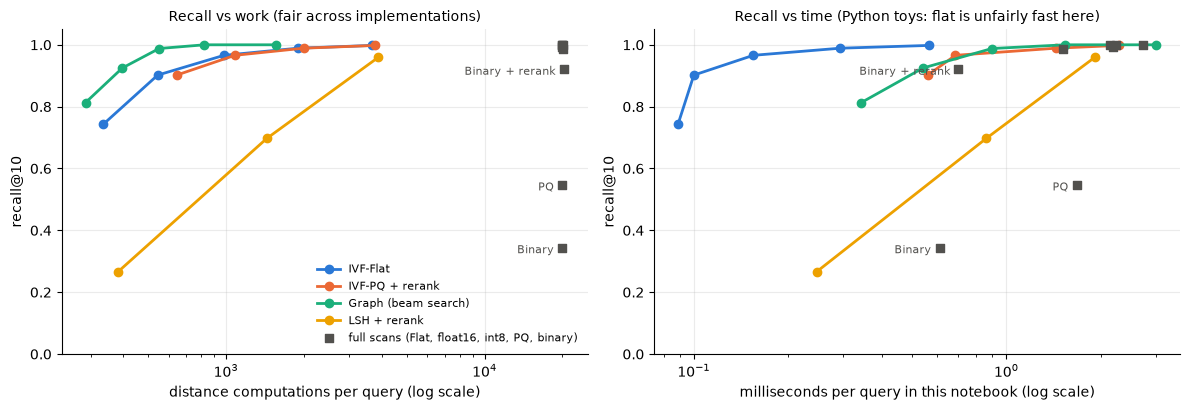

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
families = [("IVF-Flat", "IVF-Flat"), ("IVF-PQ + rerank 100", "IVF-PQ + rerank"), ("Graph (Vamana-style)", "Graph (beam search)"),
            ("LSH (8 bits)", "LSH + rerank")]
for ax, xcol, xlabel in [(axes[0], "distances/query", "distance computations per query (log scale)"),
                         (axes[1], "ms/query", "milliseconds per query in this notebook (log scale)")]:
    for color, (key, label) in zip(COLORS, families):
        sub = df_vec[df_vec["index"] == key].sort_values(xcol)
        ax.plot(sub[xcol], sub["recall@10"], "-o", lw=2, ms=6, color=color, label=label)
    # full-scan variants (flat and quantized scans): gray squares; the low-recall ones get a direct label
    scans = df_vec[df_vec["index"].isin(["Flat (exact)", "SQ float16", "SQ int8", "PQ (8 bytes)", "Binary (1 bit/dim)"])]
    ax.scatter(scans[xcol], scans["recall@10"], marker="s", s=40, color="#52514e", zorder=3,
               label="full scans (Flat, float16, int8, PQ, binary)")
    for _, r in scans[scans["recall@10"] < 0.95].iterrows():
        name = {"PQ (8 bytes)": "PQ", "Binary (1 bit/dim)": "Binary"}[r["index"]] + (" + rerank" if "rerank" in r["setting"] else "")
        ax.annotate(name, (r[xcol], r["recall@10"]), textcoords="offset points", xytext=(-6, -4), ha="right", fontsize=8, color="#52514e")
    ax.set_xscale("log"); ax.set_xlabel(xlabel); ax.set_ylabel("recall@10"); ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(loc="lower right", fontsize=8, frameon=False)
axes[0].set_title("Recall vs work (fair across implementations)", fontsize=10)
axes[1].set_title("Recall vs time (Python toys: flat is unfairly fast here)", fontsize=10)
plt.tight_layout(); plt.show()

In [35]:
# Memory per vector, and what it would mean for 100 million 768-dim vectors (scaled by bytes per dimension, illustrative)
mem = (df_vec.groupby("index")["bytes/vector"].first() / D).rename("bytes per dimension").to_frame()
mem["GB for 100M x 768-dim"] = (mem["bytes per dimension"] * 768 * 100e6 / 1e9).round(0)
mem["best recall@10 seen"] = df_vec.groupby("index")["recall@10"].max()
mem.sort_values("bytes per dimension")

,bytes per dimension,GB for 100M x 768-dim,best recall@10 seen
index,,,
Binary (1 bit/dim),0.125000,10.0,0.921
PQ (8 bytes),0.125000,10.0,0.988
IVF-PQ + rerank 100,0.187500,14.0,0.998
SQ int8,1.000000,77.0,1.000
SQ float16,2.000000,154.0,1.000
Flat (exact),4.000000,307.0,1.000
IVF-Flat,4.062500,312.0,0.998
LSH (8 bits),4.250000,326.0,0.959
Graph (Vamana-style),5.064063,389.0,1.000


**How to read these results:**

- **The frontier** is the set of points where nothing else is both cheaper and more accurate. On the left plot, graph search and IVF reach high recall while touching a small fraction of the vectors; LSH needs many more candidates for the same recall.
- **Memory** is the other axis. Graph and IVF-Flat keep full vectors (plus edges or ids). int8, PQ and binary cut memory by 4x, 32x and 32x here, and get most of the recall back with re-ranking; but re-ranking needs the full vectors *somewhere* (often on disk).
- **Real systems combine the pieces:** IVF + PQ + re-rank (FAISS IVF-PQ), graph + int8 or binary + re-rank (many vector databases), graph on SSD + PQ in RAM (DiskANN).
- **Never trust one number.** Always report recall *at* a given latency and memory budget, measured on *your* embeddings and *your* queries. Public benchmarks such as ann-benchmarks and big-ann-benchmarks do exactly this.

## 6. Vector indexes in production

### 6.1 Filtered vector search: pre-filter, post-filter, in-graph filtering

**The task:** "the 10 most similar vectors **where** `category = 'shoes'` (or `tenant_id = 42`, or `price < 50`)". This is the vector version of a composite index question: two conditions, and the order in which you apply them changes speed **and** correctness.

| Strategy | How it works | Good when | Problem |
|---|---|---|---|
| **Post-filter** | ANN search for top-k (or top-k x some factor), then drop the ones that fail the filter | filter keeps most vectors (say > 20-50%) | with a selective filter, most results are dropped and you return **fewer than k** or wrong results |
| **Pre-filter + exact scan** | find matching ids first (with a normal DB index), then brute-force only those | filter keeps few vectors (say < 1-5%, or a few thousand) | slow if the filter keeps many vectors |
| **In-graph filtering, strict** | walk only through nodes that pass the filter | rarely a good idea alone | the graph **falls apart** into islands when few nodes pass; recall collapses |
| **In-graph filtering, filter-aware** | walk through all nodes, but only passing nodes enter the result list; keep going until k pass | medium selectivity | cost grows as the filter gets more selective (more non-matching nodes to walk through) |

Real engines mix these with a **planner**, just like a SQL planner using selectivity (as of late 2026): for example Qdrant estimates filter cardinality and switches to an exact payload-index scan for small result sets, and builds extra graph links for indexed payload fields; Weaviate offers ACORN-style filter-aware traversal; pgvector 0.8+ has **iterative index scans** (`hnsw.iterative_scan`) that keep scanning the index when the `WHERE` clause removed too many results; Filtered-DiskANN builds label-aware graphs. Details differ by product, so check the docs.

We test all four on our graph with a random filter that keeps 50%, 10%, 2% and 0.5% of the vectors.

In [36]:
attr = rng.random(N)                                         # a random attribute per vector, filter = attr < s
filter_rows = []
for s in [0.5, 0.1, 0.02, 0.005]:
    allowed = attr < s
    allowed_ids = np.flatnonzero(allowed)
    QF = Q[:100]                                                 # 100 queries keep this cell quick
    gt_f = [allowed_ids[np.argsort(sqnorm(X[allowed_ids] - q))[:K]] for q in QF]  # exact filtered top-10
    strategies = {
        "post-filter (ANN top-10, then filter)": lambda q: (lambda r: (r[0][allowed[r[0]]], r[1]))(graph_search(q, graph, 40, k=10)),
        "post-filter, oversample 10x (top-100)": lambda q: (lambda r: (r[0][allowed[r[0]]][:K], r[1]))(graph_search(q, graph, 100, k=100)),
        "pre-filter + exact scan": lambda q: (allowed_ids[np.argsort(sqnorm(X[allowed_ids] - q))[:K]], len(allowed_ids)),
        "in-graph strict (walk only allowed)": lambda q: graph_search(q, graph, 40, allowed=allowed, mode="strict")[:2],
        "in-graph filter-aware (walk all)": lambda q: graph_search(q, graph, 40, allowed=allowed, mode="aware")[:2],
    }
    for name, fn in strategies.items():
        t0 = time.perf_counter(); out = [fn(q) for q in QF]; ms = (time.perf_counter() - t0) / len(QF) * 1000
        filter_rows.append({"filter keeps": f"{s:.1%}", "strategy": name, "recall@10": round(recall_at_k([o[0] for o in out], gt_f), 3),
                            "avg results returned": round(np.mean([len(o[0]) for o in out]), 1),
                            "distances/query": int(np.mean([o[1] for o in out])), "ms/query": round(ms, 2)})
df_filter = pd.DataFrame(filter_rows)
df_filter.pivot(index="strategy", columns="filter keeps", values="recall@10")[["50.0%", "10.0%", "2.0%", "0.5%"]]

filter keeps,50.0%,10.0%,2.0%,0.5%
strategy,,,,
in-graph filter-aware (walk all),0.999,0.996,0.999,1.000
in-graph strict (walk only allowed),0.883,0.216,0.002,0.004
"post-filter (ANN top-10, then filter)",0.495,0.097,0.014,0.008
"post-filter, oversample 10x (top-100)",0.999,0.883,0.206,0.055
pre-filter + exact scan,1.000,1.000,1.000,1.000


In [37]:
df_filter.pivot(index="strategy", columns="filter keeps", values="distances/query")[["50.0%", "10.0%", "2.0%", "0.5%"]]

filter keeps,50.0%,10.0%,2.0%,0.5%
strategy,,,,
in-graph filter-aware (walk all),834,3773,13104,19254
in-graph strict (walk only allowed),333,96,2,2
"post-filter (ANN top-10, then filter)",558,558,558,558
"post-filter, oversample 10x (top-100)",985,985,985,985
pre-filter + exact scan,10016,1991,390,116


**What the two tables show:**

- **Plain post-filtering** returns too few results even with a loose filter: at 50% about half of the 10 results are dropped, so recall is about 0.5. **Oversampling** (fetch 100, keep the first 10 that pass) fixes loose filters, but fails once the filter is more selective than the oversampling factor (at 2% only about 2 of 100 candidates pass).
- **Strict in-graph filtering** loses recall as the filter tightens: when only a few percent of nodes may be walked through, the allowed nodes are no longer connected to each other, so the walk gets stuck. *This is why HNSW + a strict filter can silently lose recall*, and why engines add extra links, filter-aware traversal or fall back to exact search.
- **Filter-aware traversal** keeps recall high, but its cost rises as the filter gets more selective.
- **Pre-filter + exact scan** is always exact, and becomes the *cheapest* option for very selective filters (only 100 vectors to compare at 0.5%).

**Rule:** estimate how many vectors pass the filter, exactly like a SQL planner estimates selectivity. Few -> pre-filter and scan. Many -> ANN with post-filter or filter-aware traversal. In between -> filter-aware traversal or iterative scans. And index the filter columns themselves (a B-tree or payload index), so the pre-filter step is fast.

### 6.2 Multi-tenancy: one shared index or one index per tenant?

**Multi-tenancy** = many customers (tenants) share one system, and each must only see its own data. It is the vector version of the **partial index** question.

| Design | How | Pros | Cons |
|---|---|---|---|
| **Shared index + tenant filter** | one big index, `WHERE tenant_id = ?` | simple; good for many tiny tenants; one index to maintain | every query is a filtered query (section 6.1); risk of leaking data if a filter is forgotten |
| **Index (or partition / collection / namespace) per tenant** | separate small index per tenant | isolation, no filter needed, per-tenant deletes are easy (drop it) | overhead per index; thousands of tiny HNSW graphs waste memory; small tenants are better served by flat scan |
| **Hybrid** | small tenants: flat scan of their rows (pre-filter); big tenants: their own ANN index | best of both | more logic |

Many products have a first-class concept for this (namespaces, partitions, partition keys, tenant shards); names differ, as of late 2026. Below: tenants with very different sizes (a few big, many small).

In [38]:
tenant_p = 1 / np.arange(1, 301) ** 1.2; tenant_p /= tenant_p.sum()
tenant = rng.choice(300, N, p=tenant_p)                      # 300 tenants: tenant 0 is big, most are small
sizes = np.bincount(tenant)
rows_t = []
for t_id in [0, 5, 60]:
    ids = np.flatnonzero(tenant == t_id)
    if len(ids) < K: continue
    allowed = tenant == t_id
    gt_t = [ids[np.argsort(sqnorm(X[ids] - q))[:K]] for q in Q[:40]]
    aware = [graph_search(q, graph, 40, allowed=allowed, mode="aware")[:2] for q in Q[:40]]
    rows_t.append({"tenant": t_id, "tenant size": len(ids),
                   "shared graph + filter-aware: recall": round(recall_at_k([a[0] for a in aware], gt_t), 3),
                   "shared graph: distances/query": int(np.mean([a[1] for a in aware])),
                   "own flat index: recall": 1.0, "own flat index: distances/query": len(ids)})
print("number of tenants:", (sizes > 0).sum(), "| biggest:", sizes.max(), "| tenants with < 20 vectors:", ((sizes > 0) & (sizes < 20)).sum())
pd.DataFrame(rows_t)

number of tenants: 300 | biggest: 4905 | tenants with < 20 vectors: 194


,tenant,tenant size,shared graph + filter-aware: recall,shared graph: distances/query,own flat index: recall,own flat index: distances/query
0,0,4905,0.995,1573,1.0,4905
1,5,596,1.000,9743,1.0,596
2,60,31,1.000,20065,1.0,31


For small tenants, a "partial index" (here simply a flat scan of that tenant's own vectors) is both exact and cheaper than walking the shared graph. For the biggest tenant, a flat scan gets expensive, and that is where a dedicated ANN index (or the shared one) pays off.

### 6.3 Updates and deletes: tombstones, degraded recall, rebuilds

**Why it is hard:** removing a node from a graph also removes the paths that went *through* it. IVF is easier (remove the id from its list) but suffers from **drift**: the centroids were trained on old data.

**The usual approach (the same as LSM trees and PostgreSQL VACUUM):**
1. **Tombstone**: mark the vector as deleted; keep it in the graph so paths still work; skip it in results.
2. Over time tombstones waste memory and search work (the search still walks through them).
3. **Repair or rebuild** in the background: reconnect neighbours around deleted nodes (FreshDiskANN-style consolidation, HNSW "replace deleted" options) or rebuild the segment, then drop the tombstones.

**Updates** are usually "delete + insert". In pgvector, the index is a normal PostgreSQL index, so deleted tuples are cleaned by `VACUUM` like any other index; a heavily changed HNSW index can be rebuilt with `REINDEX INDEX CONCURRENTLY`.

We delete half of the vectors at random and compare three strategies against the exact answer over the vectors that remain.

In [39]:
alive = rng.random(N) > 0.5                                      # delete about 50% of vectors
alive_ids = np.flatnonzero(alive)
gt_alive = [alive_ids[np.argsort(sqnorm(X[alive_ids] - q))[:K]] for q in Q]

# (a) tombstones: graph unchanged, deleted nodes are walked through but never returned
# (b) hard delete without repair: deleted nodes and every edge to them are simply removed
graph_hard = [g[alive[g]] if alive[i] else np.empty(0, dtype=int) for i, g in enumerate(graph)]

def run_case(label, g, mode, ef=40):
    # mode 'strict' only walks alive nodes (deleted ones are gone); 'aware' walks through tombstones
    t0 = time.perf_counter(); out = [graph_search(q, g, ef, allowed=alive, mode=mode)[:2] for q in Q]
    ms = (time.perf_counter() - t0) / NQ * 1000
    return {"strategy": label, "recall@10": round(recall_at_k([o[0] for o in out], gt_alive), 3),
            "distances/query": int(np.mean([o[1] for o in out])), "ms/query": round(ms, 2)}

rows_del = [run_case("(a) tombstones (filter-aware)", graph, "aware"),
            run_case("(b) hard delete, no repair", graph_hard, "strict")]
print("after the hard delete, the surviving graph is split into", n_components(graph_hard) - (~alive).sum(), "pieces")

after the hard delete, the surviving graph is split into 5 pieces


For (c) we **rebuild** a fresh graph from the surviving vectors only, then map its local ids back to the original ids.

In [40]:
t0 = time.perf_counter()
graph_alive = build_graph(X[alive_ids])                            # build on the ~10k live vectors only
graph_rebuilt = [np.empty(0, dtype=int)] * N
for j, g in enumerate(graph_alive):
    graph_rebuilt[alive_ids[j]] = alive_ids[g]                      # local id -> original id
rebuild_s = time.perf_counter() - t0
rows_del.append(run_case(f"(c) rebuild on live vectors ({rebuild_s:.1f}s)", graph_rebuilt, "strict"))
pd.DataFrame(rows_del)

,strategy,recall@10,distances/query,ms/query
0,(a) tombstones (filter-aware),0.999,835,1.40
1,"(b) hard delete, no repair",0.900,336,0.78
2,(c) rebuild on live vectors (2.7s),0.999,491,0.85


**Reading the result:**

- **Tombstones** keep recall high (the paths still exist) but the search does extra work walking through dead nodes, and their memory is not given back.
- **Hard delete without repair** cuts paths and lowers recall: the graph is now a worse map.
- **Rebuild** restores recall and the lower cost, but costs a full build (here a few seconds; for a big index, hours of CPU). Real systems therefore rebuild **segments** in the background, LSM-style.

**IVF drift, briefly:** if new data comes from a region the k-means centroids never saw (a new product line, a new language), it all lands in the few nearest lists. Lists become unbalanced, queries in that region scan huge lists, and recall at a fixed `nprobe` can drop. The fix is re-training the centroids (a rebuild). Let us see the imbalance.

In [41]:
old = x_labels < 40                                               # train IVF on clusters 0..39 only
km_old = KMeans(80, n_init=1, max_iter=25, random_state=SEED).fit(X[old])
new_assign = km_old.predict(X[~old])                              # new data (clusters 40..49) arrives later
sizes_before = np.bincount(km_old.labels_, minlength=80)
sizes_after = sizes_before + np.bincount(new_assign, minlength=80)
km_new = KMeans(80, n_init=1, max_iter=25, random_state=SEED).fit(X)
sizes_retrained = np.bincount(km_new.labels_, minlength=80)
pd.DataFrame({"list sizes": ["before new data", "new data added, old centroids", "after re-training"],
              "largest list": [sizes_before.max(), sizes_after.max(), sizes_retrained.max()],
              "largest / average": [round(s.max() / s.mean(), 1) for s in (sizes_before, sizes_after, sizes_retrained)]})

,list sizes,largest list,largest / average
0,before new data,428,2.1
1,"new data added, old centroids",624,2.5
2,after re-training,438,1.8


In this mild synthetic example the largest list grows from about 2.1x to 2.5x the average size, and re-training brings it back down. Real drift (a new language, a new product line, a new embedding model version) can be much stronger, and it also lowers recall at a fixed `nprobe`. Graph indexes drift less in this sense, because new points are linked to their actual neighbours when inserted.

### 6.4 Sparse vector indexes (SPLADE-style)

**What a sparse vector is:** a vector with tens of thousands of dimensions (one per vocabulary word or token) where almost all values are zero. Learned sparse models such as **SPLADE** output a weight for each important term, including related terms that are not in the text. BM25 can also be seen as a sparse vector.

**How it is indexed:** with an **inverted index**, exactly like full-text search (the database cousin in the mapping table): term -> list of (doc id, weight). Score = sum over the query's terms of `query weight x doc weight`. Only the posting lists of the query's few terms are read. Engines speed this up further by skipping documents that cannot make the top-k (algorithms such as WAND, MaxScore, block-max WAND).

SPLADE and hybrid search are covered in [advanced retrieval, section 6](../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb). Here is the index itself, on toy SPLADE-like data.

In [42]:
V_TERMS, N_DOCS = 30_000, 20_000
term_p = 1 / np.arange(1, V_TERMS + 1) ** 0.8; term_p /= term_p.sum()
doc_terms = [np.unique(row) for row in rng.choice(V_TERMS, (N_DOCS, 40), p=term_p)]   # up to 40 active terms per doc
doc_w = [rng.gamma(2, 0.5, len(t)).astype(np.float32) for t in doc_terms]
S = sparse.csr_matrix((np.concatenate(doc_w), np.concatenate(doc_terms), np.r_[0, np.cumsum([len(t) for t in doc_terms])]),
                      shape=(N_DOCS, V_TERMS))

postings = S.tocsc()                                            # column = term -> (doc ids, weights): the inverted index
def sparse_search(q_terms, q_weights, k=K):
    scores = np.zeros(N_DOCS, dtype=np.float32); touched = 0
    for t, w in zip(q_terms, q_weights):
        lo, hi = postings.indptr[t], postings.indptr[t + 1]
        np.add.at(scores, postings.indices[lo:hi], w * postings.data[lo:hi]); touched += hi - lo
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])], touched

q_terms = np.unique(rng.choice(V_TERMS, 8, p=term_p)); q_w = rng.gamma(2, 0.5, len(q_terms)).astype(np.float32)
top, touched = sparse_search(q_terms, q_w)
qv = sparse.csr_matrix((q_w, q_terms, [0, len(q_terms)]), shape=(1, V_TERMS))
brute = (S @ qv.T).toarray().ravel()
print("same top-10 as brute force:", set(top) == set(np.argsort(-brute)[:K]))
print(f"postings read: {touched:,} of {S.nnz:,} stored non-zeros ({touched / S.nnz:.1%})")

same top-10 as brute force: True
postings read: 2,458 of 776,104 stored non-zeros (0.3%)


As of late 2026, sparse vectors are supported natively by several engines (for example pgvector's `sparsevec` type, Qdrant and Milvus sparse indexes, Elasticsearch/OpenSearch learned-sparse fields). Combining a sparse and a dense index and fusing the scores is **hybrid search**.

### 6.5 Multi-vector indexes (late interaction, ColBERT-style)

**What it is:** instead of one vector per document, store **one vector per token** (ColBERT). Score a document with **MaxSim**: for each query token, take its best match among the document's tokens, and add these up. More accurate for fine-grained matching; many more vectors to store.

**How it is indexed (the common pattern):**
1. Put **all token vectors** into one ANN index (often heavily compressed, as in ColBERTv2 / PLAID).
2. Search with each query token; collect the documents those token hits belong to (**candidate generation**).
3. Compute exact MaxSim only for the candidates (**re-ranking**).

Explained in more depth in [advanced retrieval, section 4](../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb) and [every RAG type, 5.5 and 5.7](../08_LLM/02_rag/05_every_rag_type_explained.ipynb). A tiny demo:

In [43]:
n_docs, tok_per_doc, dim = 500, 16, 32
tok = rng.normal(size=(n_docs * tok_per_doc, dim)).astype(np.float32)
tok /= np.linalg.norm(tok, axis=1, keepdims=True)
tok_doc = np.repeat(np.arange(n_docs), tok_per_doc)             # which document each token vector belongs to
qtok = tok[37 * tok_per_doc: 37 * tok_per_doc + 4] + rng.normal(0, 0.05, (4, dim)).astype(np.float32)   # 4 query tokens resembling doc 37

def maxsim(qt, doc_id):
    dt = tok[tok_doc == doc_id]
    return float((qt @ dt.T).max(1).sum())                      # best match per query token, summed

# step 1-2: per query token, top-20 token hits from the (here flat) token index -> candidate documents
hits = np.argsort(-(qtok @ tok.T), axis=1)[:, :20]
cands = np.unique(tok_doc[hits])
# step 3: exact MaxSim on candidates only
ranked = sorted(cands, key=lambda d: -maxsim(qtok, d))
print(f"{len(tok)} token vectors indexed; {len(cands)} candidate docs re-ranked; best doc = {ranked[0]} (expected 37)")

8000 token vectors indexed; 72 candidate docs re-ranked; best doc = 37 (expected 37)


### 6.6 Matryoshka truncation: a smaller index from shorter vectors

**What it is:** **Matryoshka Representation Learning (MRL)** trains embedding models so that the **first** dimensions carry the most information. You can cut a 1024-dim vector to 256 dims and still get good results. For indexing, that means: build the ANN index on short vectors (less memory, faster), and **re-rank** with the full vectors. Background: [sentence embeddings, section 6](../07_NLP/09_sentence_embeddings_advanced.ipynb).

Our random vectors are not Matryoshka-trained, so as a **stand-in** we rotate them with PCA, which also puts the most informative directions first. (With a real MRL model you would just slice the vector.)

In [44]:
pca = PCA(D, random_state=SEED).fit(X)
Xp, Qp = pca.transform(X).astype(np.float32), pca.transform(Q).astype(np.float32)
rows_m = []
for dims in [8, 16, 32, 64]:
    short = Xp[:, :dims]
    res, res_rr = [], []
    for q in Qp:
        d = sqnorm(short - q[:dims]); cand = np.argpartition(d, 50)[:50]
        res.append(cand[np.argsort(d[cand])][:K])
        res_rr.append(cand[np.argsort(sqnorm(Xp[cand] - q))][:K])     # re-rank with all 64 dims
    rows_m.append({"dims kept": dims, "bytes/vector": dims * 4, "recall@10 (short only)": round(recall_at_k(res), 3),
                   "recall@10 (+ rerank 50 with full)": round(recall_at_k(res_rr), 3)})
pd.DataFrame(rows_m)

,dims kept,bytes/vector,recall@10 (short only),recall@10 (+ rerank 50 with full)
0,8,32,0.117,0.326
1,16,64,0.343,0.737
2,32,128,0.649,0.983
3,64,256,1.000,1.000


## 7. Choosing an index

### 7.1 Which database index?

| Your query or data | Index to try | Notes |
|---|---|---|
| `=`, ranges, `ORDER BY`, prefix `LIKE 'abc%'` | **B-tree** | the default; most queries |
| several conditions together | **composite B-tree** | equality columns first, range/sort column last (leftmost-prefix rule) |
| a hot query reading a few columns | **covering index** (`INCLUDE` in PostgreSQL) | avoids table lookups; watch the size |
| queries always on a small subset (`status = 'pending'`, `deleted_at IS NULL`) | **partial index** | tiny and fast; query must imply the index's `WHERE` |
| condition on a computed value (`lower(email)`, a JSON field, a date part) | **expression index** | query must use the same expression |
| arrays, JSONB containment, full-text search, `ILIKE '%x%'` | **GIN** (+ `pg_trgm` for substrings) | slower writes; great reads |
| geometry, ranges, overlap, "nearest point" | **GiST** (or SP-GiST), R-tree in SQLite | also exclusion constraints |
| huge append-only, time-ordered table | **BRIN** | tiny; needs physical order |
| low-cardinality column in a data warehouse | **bitmap index** (Oracle) or a columnar engine's built-ins | not in PostgreSQL as a stored index (it builds bitmaps on the fly) |
| very high write rate (logs, events) | **few indexes**, or an LSM-based store | every index slows every write |
| small table or low selectivity | **no index** | a scan is fine |

### 7.2 Which vector index?

Numbers below are rough rules of thumb (as of late 2026) and depend on dimension, hardware and recall target. Always measure on your own data.

| Situation | Index to try | Why |
|---|---|---|
| up to about 100k vectors, or exact results required | **Flat** (brute force) | simple, exact, often fast enough with SIMD/GPU |
| fits in RAM, needs high recall and low latency | **HNSW** (often with int8/float16 vectors) | best recall/latency trade-off in memory for most workloads |
| very large, memory-limited, can tolerate some loss | **IVF-PQ + re-rank** (or ScaNN) | 10-100x less memory; re-rank restores recall |
| larger than RAM, SSD available | **DiskANN / Vamana-style** | PQ in RAM, graph + full vectors on SSD |
| frequent bulk rebuilds OK, fast build needed | **IVF-Flat** / IVF-SQ8 | builds much faster than HNSW; recall depends on `nprobe` |
| very high-dimensional embeddings that tolerate it, huge scale | **binary quantization + re-rank** | 32x smaller, very fast first pass |
| many selective metadata filters | pre-filter + flat for small result sets; **filter-aware HNSW** / iterative scans otherwise | see section 6.1 |
| many tenants of very different sizes | partitions/namespaces per big tenant, filtered shared index or flat for small ones | see section 6.2 |
| heavy updates/deletes | an engine with segments + background compaction, or plan for periodic rebuilds | see section 6.3 |
| keyword-heavy queries (names, codes, rare terms) | **sparse / BM25 inverted index**, plus dense: hybrid | dense vectors miss exact rare tokens |
| fine-grained matching, re-ranking quality | **multi-vector (late interaction)** as a re-ranker | expensive in storage |

**Tuning order that usually works:** pick the index type from the table, fix the memory budget (quantization), then tune the query-time knob (`efSearch`, `nprobe`) until recall@10 meets your target on a labelled query set, and only then tune build-time knobs (`M`, `efConstruction`, `nlist`).

### 7.3 pgvector: HNSW vs IVFFlat in SQL

pgvector adds a `vector` column type and two ANN index types to PostgreSQL. Shown as markdown (not run here). Defaults and limits as of late 2026 (pgvector 0.8.x); check the README for your version.

```sql
CREATE EXTENSION IF NOT EXISTS vector;
CREATE TABLE items (id bigserial PRIMARY KEY, tenant_id int, category text, embedding vector(768));

-- Exact search (no index): a sequential scan, always correct
SELECT id FROM items ORDER BY embedding <=> '[0.1, 0.2, ...]' LIMIT 10;   -- <=> cosine distance, <-> L2, <#> negative inner product

-- HNSW: better speed/recall trade-off, slower build, more memory; can be built on an empty table
CREATE INDEX ON items USING hnsw (embedding vector_cosine_ops) WITH (m = 16, ef_construction = 64);
SET hnsw.ef_search = 100;                       -- default 40; higher = better recall, slower

-- IVFFlat: faster build, less memory; build it AFTER loading data (it trains k-means centroids)
CREATE INDEX ON items USING ivfflat (embedding vector_cosine_ops) WITH (lists = 1000);   -- rows/1000 up to 1M rows
SET ivfflat.probes = 32;                        -- default 1; a start is sqrt(lists)

-- Filtered search: a B-tree for the filter, and iterative scans so filtering does not starve the result (0.8.0+)
CREATE INDEX ON items (tenant_id);
SET hnsw.iterative_scan = relaxed_order;        -- or strict_order; off by default
SELECT id FROM items WHERE tenant_id = 42 ORDER BY embedding <=> $1 LIMIT 10;

-- Partial index per big tenant / category (the "partial index" pattern for vectors)
CREATE INDEX ON items USING hnsw (embedding vector_cosine_ops) WHERE category = 'shoes';

-- Smaller vectors: half precision and binary quantization via expression indexes
CREATE INDEX ON items USING hnsw ((embedding::halfvec(768)) halfvec_cosine_ops);
CREATE INDEX ON items USING hnsw ((binary_quantize(embedding)::bit(768)) bit_hamming_ops);
-- query the binary index, then re-rank by the full vector:
SELECT id FROM (SELECT id, embedding FROM items ORDER BY binary_quantize(embedding)::bit(768) <~> binary_quantize($1) LIMIT 100) c
ORDER BY embedding <=> $1 LIMIT 10;

-- Faster builds
SET maintenance_work_mem = '8GB';  SET max_parallel_maintenance_workers = 7;
```

| | HNSW | IVFFlat |
|---|---|---|
| Build speed | slower | faster |
| Memory / size | larger | smaller |
| Query speed at the same recall | usually better | usually worse |
| Needs data before building | no | yes (k-means training); rebuild if data drifts |
| Main query knob | `hnsw.ef_search` | `ivfflat.probes` |

### 7.4 Index names you will see in vector databases (as of late 2026)

Names and options change quickly; treat this as a map, not a spec.

| Family | Typical names |
|---|---|
| Exact | `FLAT`, brute force, `IndexFlatL2` / `IndexFlatIP` (FAISS) |
| Inverted file | `IVF_FLAT`, `IVFFlat`, `IVF_SQ8`, `IVF_PQ`, `IndexIVFPQ` |
| Graph, in memory | `HNSW` (almost every engine; Lucene-based search engines too), sometimes with `int8`/`binary`/`PQ` quantization options |
| Graph, on disk | `DISKANN`, Vamana, `StreamingDiskANN` (pgvectorscale) |
| Partition + anisotropic quantization | `SCANN` (ScaNN library; some managed databases) |
| GPU | CAGRA (NVIDIA cuVS), GPU IVF-PQ |
| Sparse | sparse inverted index, `sparsevec`, learned sparse fields |
| Tree / older | Annoy (random projection trees), KD-tree/ball tree (scikit-learn), LSH |

## 8. Recap cheat sheet

| Index | World | One-line idea | Pays | Gets | Main knob |
|---|---|---|---|---|---|
| B-tree | DB | sorted tree of keys | storage, write cost | `=`, ranges, sorting | column order |
| Composite B-tree | DB | sorted by (a, b, c) | bigger index | multi-column filters | leftmost-prefix rule; equality first, range last |
| Covering | DB | index holds all needed columns | size | no table lookups | which columns to include |
| Partial | DB | index only rows matching `WHERE` | nothing extra | tiny, fast for that subset | the predicate |
| Expression | DB | index `f(column)` | compute on write | queries on `f(column)` | same expression in the query |
| Hash | DB | key -> bucket | no ranges | O(1) equality | - |
| Bitmap | DB | bit per row per value | bad for updates | fast AND/OR | - |
| GIN / FTS | DB | element -> rows | slow writes | containment, full text | operator class |
| GiST / R-tree | DB | tree of bounding boxes | - | overlap, nearest neighbour in 2-3 dims | - |
| BRIN | DB | min/max per block | needs physical order | tiny index on huge tables | pages per range |
| LSM | DB | memtable + sorted runs + compaction | read amplification | fast writes | compaction policy |
| Flat | Vector | compare with everything | slow at scale | exact | - |
| IVF | Vector | k-means lists, search a few | training, drift | big speed-up | `nlist`, `nprobe` |
| SQ int8 / float16 | Vector | fewer bits per number | small recall loss | 4x / 2x less memory | re-rank depth |
| PQ / IVF-PQ | Vector | sub-vector codebooks, table look-ups | recall loss | 10-100x less memory | `m`, bits, `nprobe`, re-rank depth |
| Binary | Vector | 1 bit per dimension, Hamming | big recall loss alone | 32x less memory, very fast | re-rank depth |
| LSH | Vector | random hyperplane buckets | many tables, many candidates | simple, theory | bits, tables |
| HNSW | Vector | layered navigable graph | memory for edges, slow build | high recall, low latency | `M`, `efConstruction`, `efSearch` |
| DiskANN / Vamana | Vector | flat pruned graph on SSD, PQ in RAM | SSD reads | billion-scale on one machine | `R`, `L`, `alpha`, PQ size |
| ScaNN | Vector | partitions + anisotropic quantization | complexity | strong MIPS trade-off | leaves to search, re-rank depth |
| Sparse inverted | Vector | term -> (doc, weight) | vocabulary-sized vectors | exact keyword-like matching | pruning (WAND etc.) |
| Multi-vector | Vector | one vector per token, MaxSim | many vectors | fine-grained relevance | candidates to re-rank |

**Five rules to remember**
1. Every index trades storage and write speed for read speed; vector indexes also trade recall.
2. Selectivity decides: few matching rows -> use an index (or pre-filter + scan); many -> scan (or post-filter).
3. Composite order matters: equality first, range last; filtered vector search order matters just as much.
4. Compress for the first pass, re-rank with full precision for the final answer.
5. Deletes and drift degrade every index; plan for vacuum, compaction and rebuilds.

## Interview questions

1. **Why can an index make a query slower?** If the condition matches a large fraction of rows, the many random lookups through the index cost more than one sequential scan. The planner uses statistics (selectivity) to choose.
2. **What is the leftmost-prefix rule?** A composite index on `(a, b, c)` can serve conditions on `a`, `a,b` or `a,b,c`, but normally not `b` or `c` alone. Put equality columns first and the range or sort column last. Some engines can skip-scan when `a` has few distinct values.
3. **Partial vs covering index?** Partial indexes only some *rows* (`WHERE status='pending'`); covering includes extra *columns* so the table is not touched.
4. **When would you use GIN, GiST and BRIN in PostgreSQL?** GIN for "contains" questions (arrays, JSONB, full text, trigrams); GiST for overlap/geometry/ranges and nearest-neighbour; BRIN for huge naturally ordered tables (time-series logs).
5. **Why are vector indexes approximate?** Exact nearest neighbour in hundreds of dimensions cannot be pruned well (curse of dimensionality), so exact search is close to a full scan. ANN indexes give up a little recall for orders-of-magnitude less work.
6. **Explain HNSW's M, efConstruction and efSearch.** M = links per node (memory, recall); efConstruction = beam width at build (graph quality, build time); efSearch = beam width at query time (recall vs latency, tunable per query, must be >= k).
7. **IVF: what are nlist and nprobe and how do you set them?** nlist = number of k-means clusters (around sqrt(N) to a few times that); nprobe = clusters searched per query; raise nprobe until recall meets the target.
8. **Why does HNSW + a strict metadata filter lose recall, and what are the fixes?** Walking only through matching nodes disconnects the graph when the filter is selective. Fixes: pre-filter + exact scan for small sets, filter-aware traversal (walk all, return only matches), iterative scans, extra links for filter values (Qdrant), label-aware graphs (Filtered-DiskANN), or partitioning by the filter.
9. **How does DiskANN serve a billion vectors on one machine?** A Vamana graph with few hops is stored on SSD with each node's vector and neighbours in one block; only PQ codes stay in RAM to guide the search; final results are re-ranked with the full vectors read from disk.
10. **What happens when you delete many vectors from an HNSW index?** They are usually tombstoned: still traversed, not returned. Search work and memory grow until the index is repaired or rebuilt (compaction). Hard deletion without repair breaks paths and lowers recall.
11. **What is the core idea of ScaNN's anisotropic quantization?** For inner-product search, quantization error parallel to a data point changes the scores of top results more than orthogonal error, so the loss weights parallel error more.
12. **int8 vs PQ vs binary quantization?** int8: 4x smaller, small loss. PQ: 10-100x smaller, larger loss, needs training. Binary: 32x smaller, large loss alone, very fast Hamming distance. All three are normally followed by re-ranking with full vectors.

## Further reading

- Yu. A. Malkov and D. A. Yashunin, "Efficient and robust approximate nearest neighbor search using Hierarchical Navigable Small World graphs", IEEE TPAMI 2018 (arXiv:1603.09320).
- H. Jégou, M. Douze, C. Schmid, "Product Quantization for Nearest Neighbor Search", IEEE TPAMI 2011.
- S. Jayaram Subramanya et al., "DiskANN: Fast Accurate Billion-point Nearest Neighbor Search on a Single Node", NeurIPS 2019. Follow-ups: FreshDiskANN (2021) and Filtered-DiskANN (2023).
- R. Guo et al., "Accelerating Large-Scale Inference with Anisotropic Vector Quantization" (ScaNN), ICML 2020 (arXiv:1908.10396).
- M. Datar, N. Immorlica, P. Indyk, V. Mirrokni, "Locality-Sensitive Hashing Scheme Based on p-Stable Distributions", SoCG 2004; M. Charikar, "Similarity Estimation Techniques from Rounding Algorithms", STOC 2002 (random hyperplanes).
- O. Khattab and M. Zaharia, "ColBERT", SIGIR 2020; T. Formal et al., "SPLADE", SIGIR 2021; A. Kusupati et al., "Matryoshka Representation Learning", NeurIPS 2022.
- Markus Winand, *Use The Index, Luke!* (use-the-index-luke.com): the best free guide to SQL indexing, including the leftmost-prefix rule and partial indexes.
- PostgreSQL documentation, chapter "Indexes" (index types, multicolumn, partial, expression, index-only scans) and the GIN, GiST, SP-GiST and BRIN chapters: postgresql.org/docs/current/indexes.html.
- SQLite documentation: "The SQLite R*Tree Module", "SQLite FTS5 Extension", "Partial Indexes", "Indexes On Expressions" and "The SQLite Query Optimizer Overview" (sqlite.org).
- pgvector README (github.com/pgvector/pgvector): HNSW and IVFFlat options, iterative index scans, halfvec / bit / sparsevec types.
- FAISS documentation and wiki ("Guidelines to choose an index"); ann-benchmarks.com and big-ann-benchmarks for public recall-vs-speed comparisons.

**Related notebooks in this repo:** [07 Indexing, B-trees and hashing](00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb), [08 Query processing](00_dbms_fundamentals/08_query_processing_and_optimization.ipynb), [Advanced data structures (LSM)](../00_AI_Fundamentals/advanced_algorithms/08_advanced_data_structures.ipynb), [Vector databases: the math](../22_ML_System_Design/05_vector_databases.ipynb), [Vector databases: products and pgvector](03_vector_db/01_vector_databases.ipynb), [Sentence embeddings (quantization, Matryoshka)](../07_NLP/09_sentence_embeddings_advanced.ipynb), [Advanced retrieval and reranking](../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb), [Every RAG type explained](../08_LLM/02_rag/05_every_rag_type_explained.ipynb).